## Evolution and composition of non-consecutive announcements

Reproduces Figure 4(a)–(d) as separate PDFs using filtered non-cons announcements and four daily statistics files derived from the original BGP announcements and repetition segments. Run from the repository root or `notebooks/` directory.

In [49]:
from pathlib import Path
import re
import pandas as pd
import numpy as np
import pyarrow.parquet as pq
import pyarrow.compute as pc
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter, MultipleLocator, FixedLocator
from tqdm.auto import tqdm
import logging

logging.getLogger().setLevel(logging.WARNING)
logging.getLogger("fontTools.ttLib.tables._h_e_a_d").setLevel(logging.ERROR)


ROOT = Path.cwd().resolve()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent
if not (ROOT / "data").exists():
    raise FileNotFoundError("Run from the repository root or notebooks/ directory")

DATA = ROOT / "data"
POISONING = DATA / "prefix.aspth.parquet" / "poisoning" / "poisoning.filtered"
STATS = DATA / "temporal_analysis"
FIGURES = ROOT / "figures" / "temporal_analysis"
FIGURES.mkdir(parents=True, exist_ok=True)

RAW_ANN = STATS / "all_announcements.daily_trend.ipv4_ipv6.stats.parquet"
RAW_PREFIX = STATS / "all_announcements.daily_unique_prefixes.ipv4_ipv6.stats.parquet"
RS_STATS = STATS / "excluded_peering_er.daily_rs_participation_ratios.from_patterns.parquet"
ORIGIN_STATS = STATS / "filtered.noncons.origin_as_rates.daily.stats.parquet"

START = pd.Timestamp("2014-01-01")
END = pd.Timestamp("2025-01-01")
EXPECTED = 396
BLUE, RED, BLACK = "#0291F7", "#F8075C", "#000000"
FONT_SIZE = 18
LINEWIDTH = 3
plt.rcParams.update({
    "font.family": "serif", "font.serif": ["cmr10"],
    "font.size": FONT_SIZE, "axes.labelsize": FONT_SIZE,
    "axes.titlesize": FONT_SIZE, "xtick.labelsize": FONT_SIZE,
    "ytick.labelsize": FONT_SIZE, "legend.fontsize": FONT_SIZE,
    "axes.unicode_minus": False, "axes.formatter.use_mathtext": True,
    "mathtext.fontset": "cm", "pdf.fonttype": 42,
})

def human_k(x, pos=None):
    if x >= 1e9: return f"{x / 1e9:.1f}B"
    if x >= 1e6: return f"{x / 1e6:.1f}M"
    if x >= 1e3: return f"{int(x / 1e3)}K"
    return f"{int(x)}"

def pct1(x, pos=None): return f"{x:.1f}%"
def pct2(x, pos=None): return f"{x:.2f}%"

def rate(num, den):
    if (den <= 0).any():
        raise ValueError("Nonpositive denominator")
    return num.astype(float).div(den.astype(float)).mul(100)

def load_daily(path, columns, aliases=None):
    df = pd.read_parquet(path)
    if aliases:
        df = df.rename(columns={k:v for k,v in aliases.items() if k in df.columns and v not in df.columns})
    missing = set(columns) - set(df.columns)
    if missing: raise ValueError(f"{path.name}: missing columns {sorted(missing)}")
    df = df[columns].copy()
    df["date"] = pd.to_datetime(df["date"])
    df = df[(df.date >= START) & (df.date < END)].sort_values("date").reset_index(drop=True)
    if len(df) != EXPECTED or df.date.duplicated().any():
        raise ValueError(f"{path.name}: expected {EXPECTED} distinct snapshots; found {len(df)}")
    return df

def merge_daily(left, right):
    if set(left.date) != set(right.date):
        raise ValueError("Snapshot dates do not match")
    return left.merge(right, on="date", validate="one_to_one").sort_values("date")

def axes_pair(heights=(1.2, 1.0), hspace=0.08):
    fig, (top, bottom) = plt.subplots(2, 1, figsize=(10, 5.5), dpi=300,
        sharex=True, constrained_layout=True,
        gridspec_kw={"height_ratios": list(heights), "hspace": hspace})
    for ax in (top, bottom):
        ax.grid(True, which="major", linestyle="--", alpha=0.30)
        ax.minorticks_off()
        ax.set_xlim(START, END)
        ax.margins(x=0, y=0.02)
    top.tick_params(axis="x", labelbottom=False)
    bottom.xaxis.set_major_locator(mdates.YearLocator())
    bottom.xaxis.set_major_formatter(mdates.DateFormatter("Jan\n%Y"))
    bottom.set_xlabel("Date", labelpad=6)
    bottom.tick_params(axis="x", pad=8)
    return fig, top, bottom

def save(fig, name):
    path = FIGURES / name
    fig.savefig(path, dpi=300, bbox_inches="tight", pad_inches=0.04)
    plt.show()
    print(f"Saved: {path}")


### Daily non-cons announcement and prefix counts

In [32]:
pattern = re.compile(r"^poisoning\.(\d{4}-\d{2}-\d{2})\.parquet$")
files = sorted(p for p in POISONING.iterdir() if p.is_file() and pattern.fullmatch(p.name))
if len(files) != EXPECTED:
    raise ValueError(f"Expected {EXPECTED} filtered announcement files; found {len(files)}")

rows = []
for path in tqdm(files, desc="Counting announcements and unique prefixes"):
    date = pd.Timestamp(pattern.fullmatch(path.name).group(1))
    pf = pq.ParquetFile(path)
    n6 = 0
    p4, p6 = set(), set()
    for batch in pf.iter_batches(columns=["prefix"], batch_size=1_000_000):
        col = batch.column("prefix")
        n6 += int(pc.sum(pc.cast(pc.match_substring(col, ":"), "int64")).as_py() or 0)
        for prefix in col.to_pylist():
            if prefix is None: continue
            (p6 if ":" in prefix else p4).add(prefix)
    total = pf.metadata.num_rows
    rows.append({"date": date, "ipv4_noncons": total - n6,
                 "ipv6_noncons": n6, "all_noncons": total,
                 "ipv4_noncons_prefixes": len(p4),
                 "ipv6_noncons_prefixes": len(p6),
                 "all_noncons_prefixes": len(p4) + len(p6)})
filtered = pd.DataFrame(rows).sort_values("date").reset_index(drop=True)
if filtered.date.duplicated().any() or not ((filtered.date >= START) & (filtered.date < END)).all():
    raise ValueError("Unexpected or duplicate filtered snapshot dates")
if int(filtered.all_noncons.sum()) != 29_228_028:
    raise ValueError("Filtered announcement total does not match filtering audit")
print(f"Validated {len(filtered)} snapshots and {int(filtered.all_noncons.sum()):,} filtered announcements")


Counting announcements and unique prefixes:   0%|          | 0/396 [00:00<?, ?it/s]

Validated 396 snapshots and 29,228,028 filtered announcements


### (a) Non-cons announcements by IP version and their relative ratio

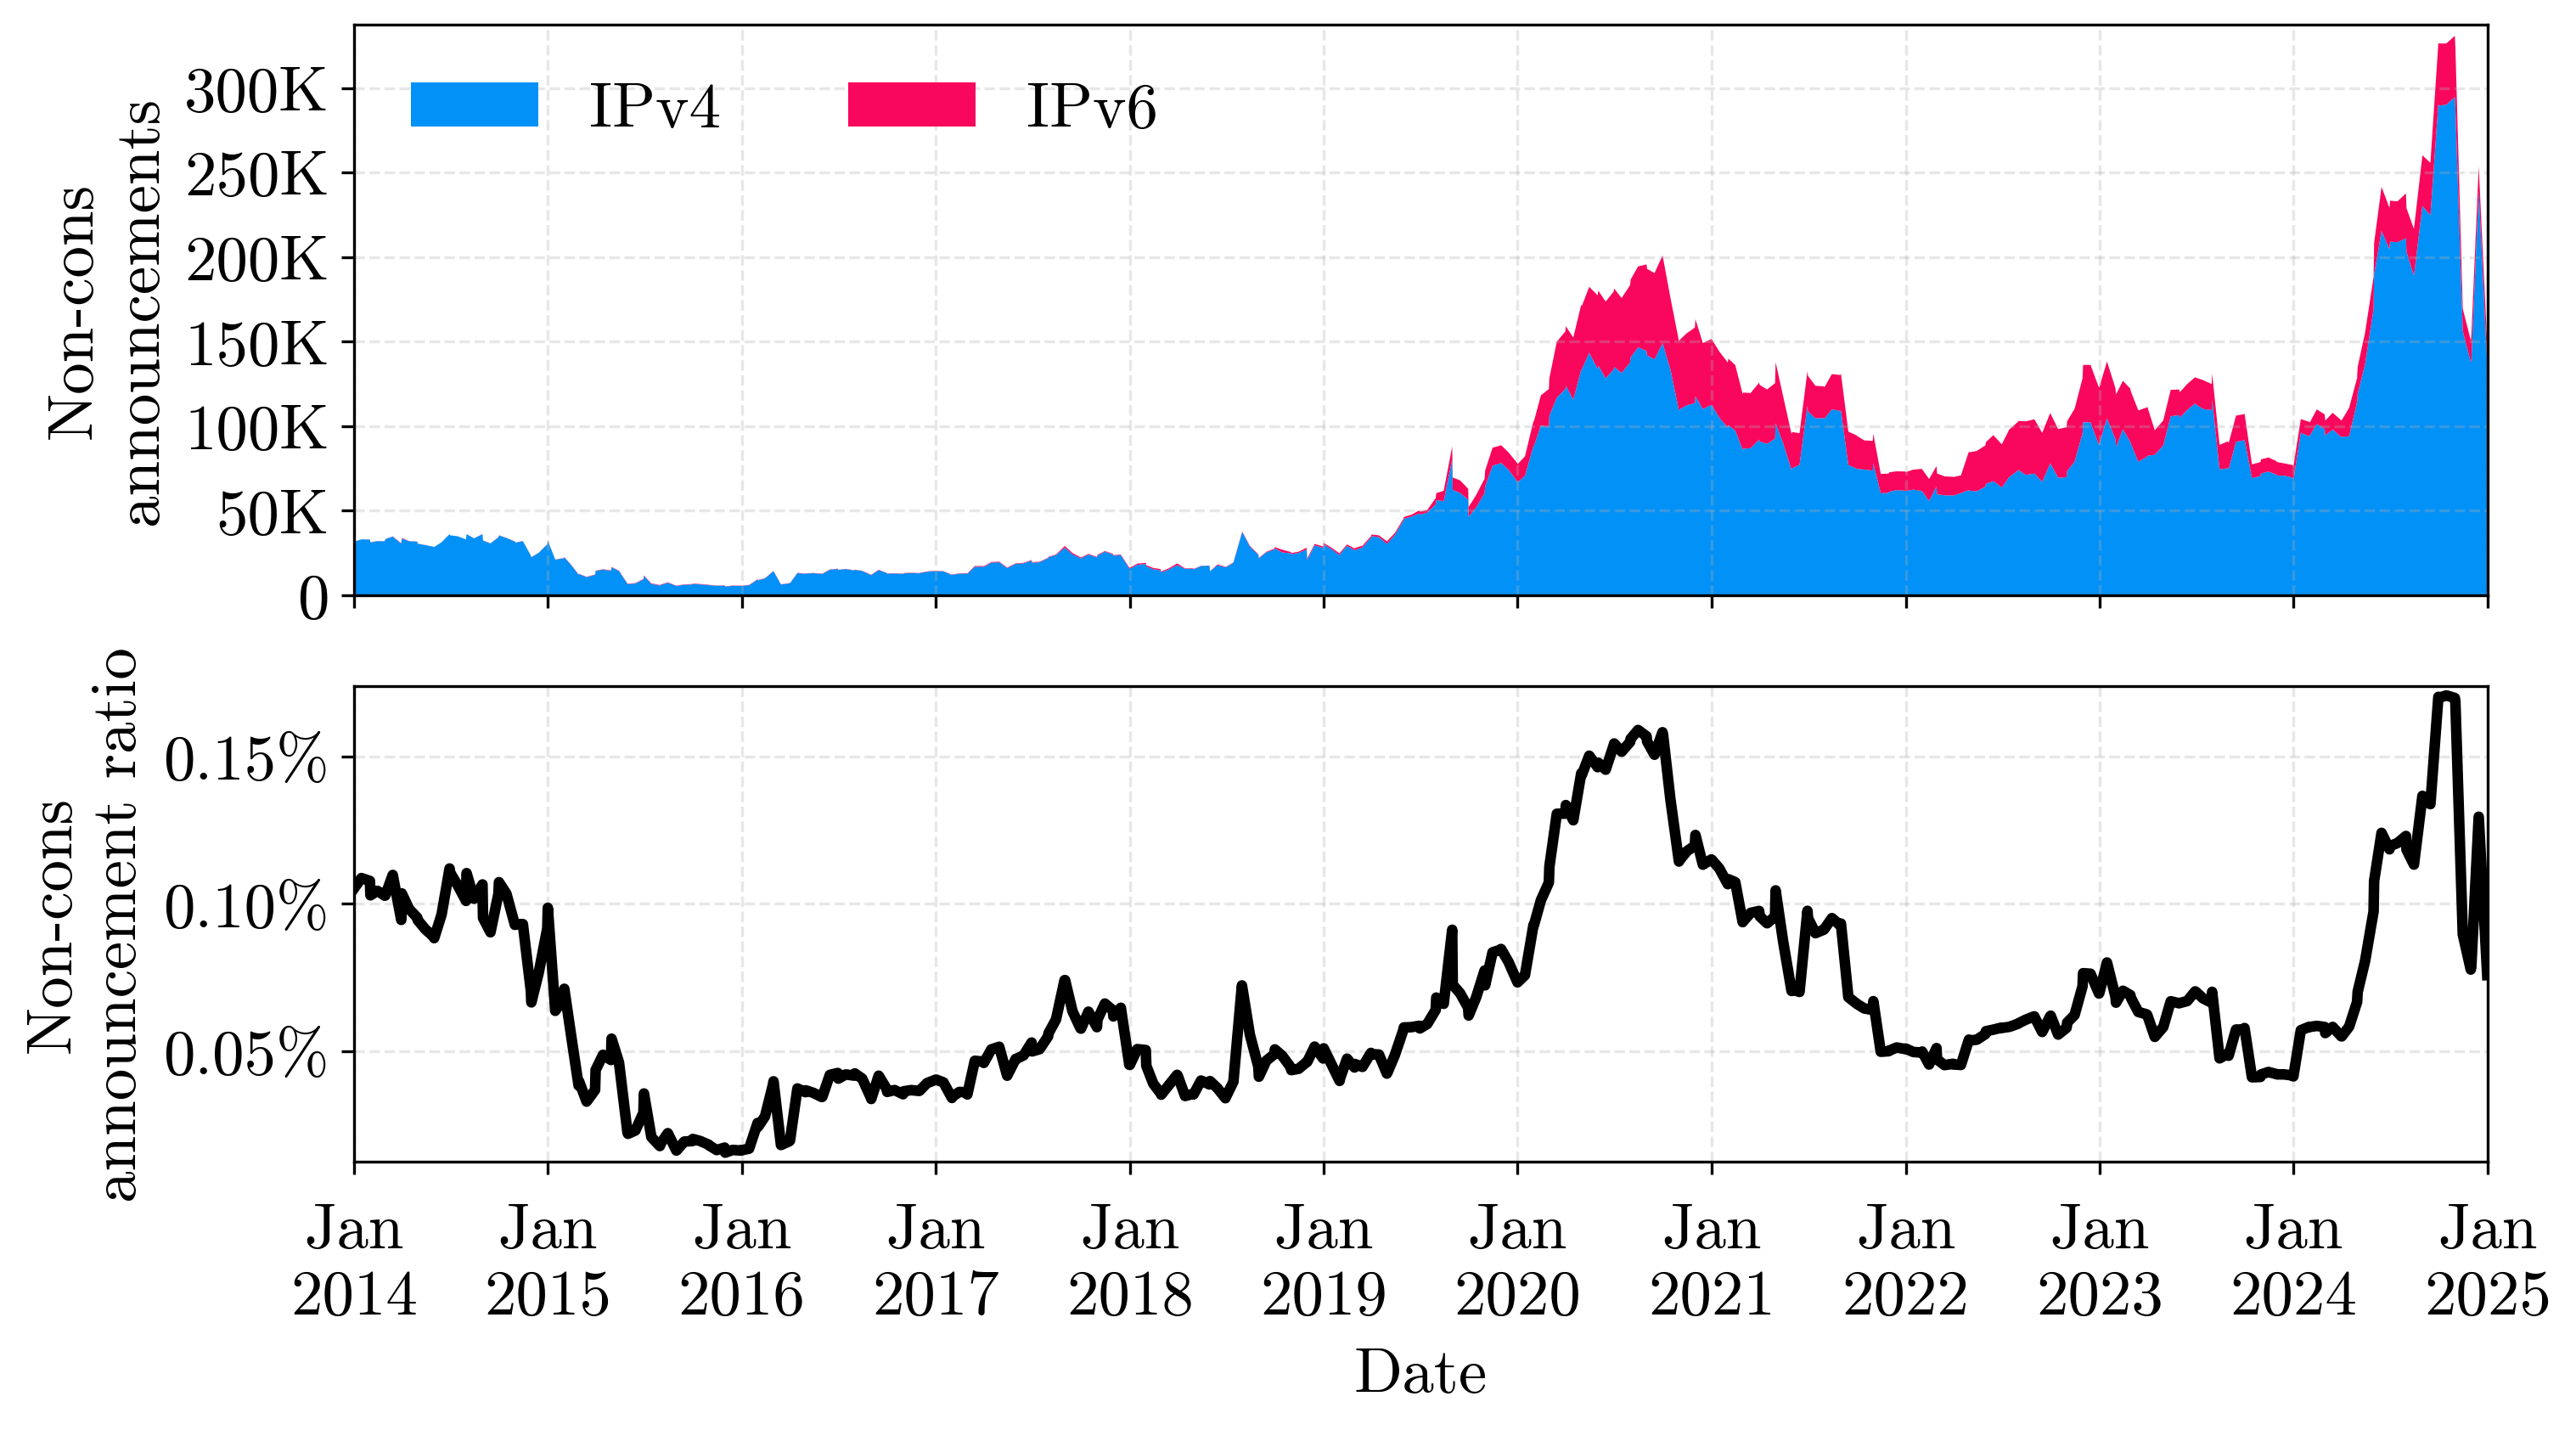

Saved: /home/savymik/Documents/as-repetition/figures/temporal_analysis/a_announcements.pdf


In [33]:

raw = load_daily(
    RAW_ANN,
    ["date", "ipv4_total", "ipv6_total", "all_total"],
    {"ipv4": "ipv4_total", "ipv6": "ipv6_total", "total": "all_total"},
)

if not (raw.ipv4_total + raw.ipv6_total == raw.all_total).all():
    raise ValueError("Raw announcement denominators do not reconcile")

a = merge_daily(
    raw,
    filtered[["date", "ipv4_noncons", "ipv6_noncons", "all_noncons"]],
)

for family in ("ipv4", "ipv6"):
    if (a[f"{family}_noncons"] > a[f"{family}_total"]).any():
        raise ValueError(f"{family} numerator exceeds denominator")

a["all_rate_pct"] = rate(a.all_noncons, a.all_total)

fig, top, bottom = axes_pair()

top.stackplot(
    a.date,
    a.ipv4_noncons,
    a.ipv6_noncons,
    labels=["IPv4", "IPv6"],
    colors=[BLUE, RED],
    alpha=1,
)
top.set_ylabel("Non-cons\nannouncements")
top.yaxis.set_major_locator(MultipleLocator(50_000))
top.yaxis.set_major_formatter(FuncFormatter(human_k))
top.legend(frameon=False, ncol=2, loc="upper left")

bottom.plot(
    a.date,
    a.all_rate_pct,
    linewidth=LINEWIDTH,
    color=BLACK,
)
bottom.set_ylabel("Non-cons\nannouncement ratio")
bottom.yaxis.set_major_formatter(FuncFormatter(pct2))

save(fig, "a_announcements.pdf")


### (b) Unique IPv4/IPv6 non-cons prefixes and their relative ratios

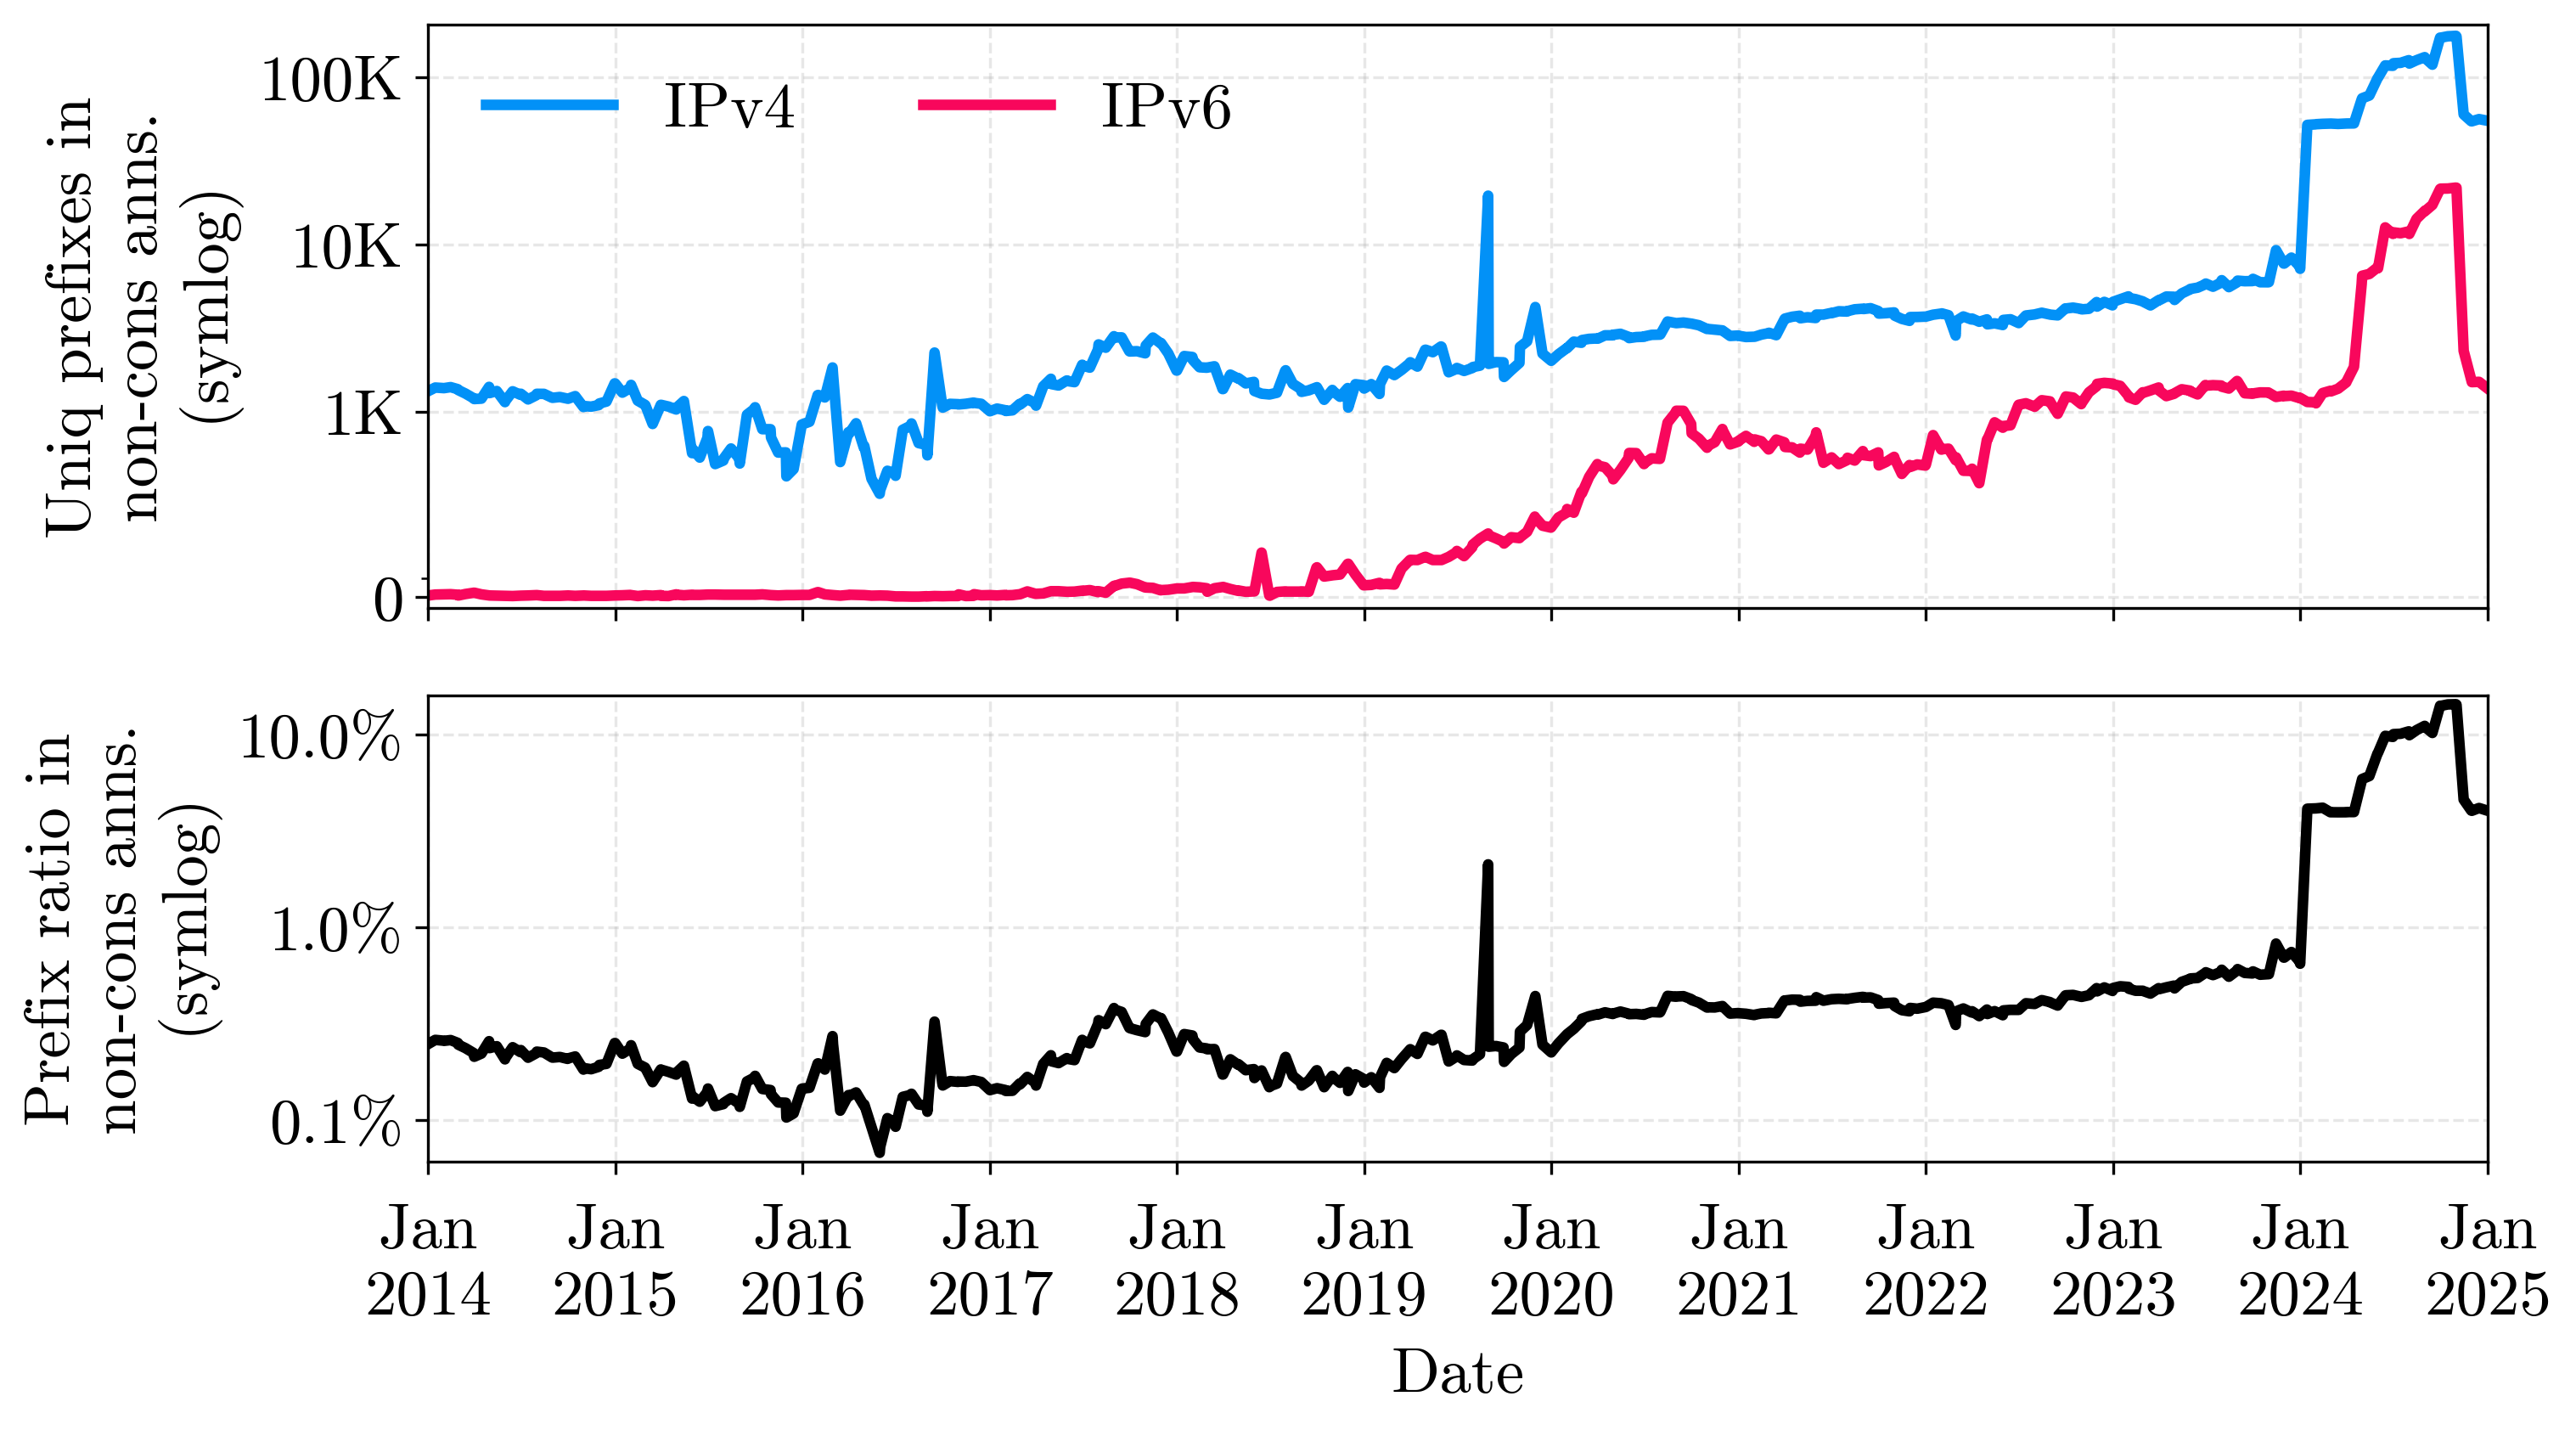

Saved: /home/savymik/Documents/as-repetition/figures/temporal_analysis/b_prefixes.pdf


In [34]:

raw_prefix = load_daily(
    RAW_PREFIX,
    ["date", "ipv4_total_prefixes", "ipv6_total_prefixes", "all_total_prefixes"],
    {
        "ipv4_unique_prefixes": "ipv4_total_prefixes",
        "ipv6_unique_prefixes": "ipv6_total_prefixes",
        "all_unique_prefixes": "all_total_prefixes",
        "ipv4_prefixes": "ipv4_total_prefixes",
        "ipv6_prefixes": "ipv6_total_prefixes",
        "all_prefixes": "all_total_prefixes",
    },)

if not (
    raw_prefix.ipv4_total_prefixes
    + raw_prefix.ipv6_total_prefixes
    == raw_prefix.all_total_prefixes
).all():
    raise ValueError("Raw unique-prefix denominators do not reconcile")

b = merge_daily(
    raw_prefix,
    filtered[
        [
            "date",
            "ipv4_noncons_prefixes",
            "ipv6_noncons_prefixes",
            "all_noncons_prefixes",
        ]
    ],
)

for family in ("ipv4", "ipv6"):
    if (
        b[f"{family}_noncons_prefixes"]
        > b[f"{family}_total_prefixes"]
    ).any():
        raise ValueError(f"{family} unique-prefix numerator exceeds denominator")

b["all_prefix_rate_pct"] = rate(
    b.all_noncons_prefixes,
    b.all_total_prefixes,)

fig, top, bottom = axes_pair((1.25, 1), 0.09)

top.plot(
    b.date,
    b.ipv4_noncons_prefixes,
    color=BLUE,
    linewidth=LINEWIDTH,
    label="IPv4",
)
top.plot(
    b.date,
    b.ipv6_noncons_prefixes,
    color=RED,
    linewidth=LINEWIDTH,
    label="IPv6",)

top.set_yscale("symlog", linthresh=1_000)
top.set_yticks([0, 1_000, 10_000, 100_000])
top.set_yticklabels(["0", "1K", "10K", "100K"])
top.set_ylabel("Uniq prefixes in\nnon-cons anns.\n (symlog)")
top.legend(frameon=False, ncol=2, loc="upper left")

bottom.plot(
    b.date,
    b.all_prefix_rate_pct,
    color=BLACK,
    linewidth=LINEWIDTH,)
bottom.set_yscale("symlog", linthresh=0.1)
bottom.yaxis.set_major_formatter(FuncFormatter(pct1))
bottom.set_ylabel("Prefix ratio in\nnon-cons anns.\n (symlog)")
save(fig, "b_prefixes.pdf")


### (c) Repeated and enclosed ASes in repetition segments

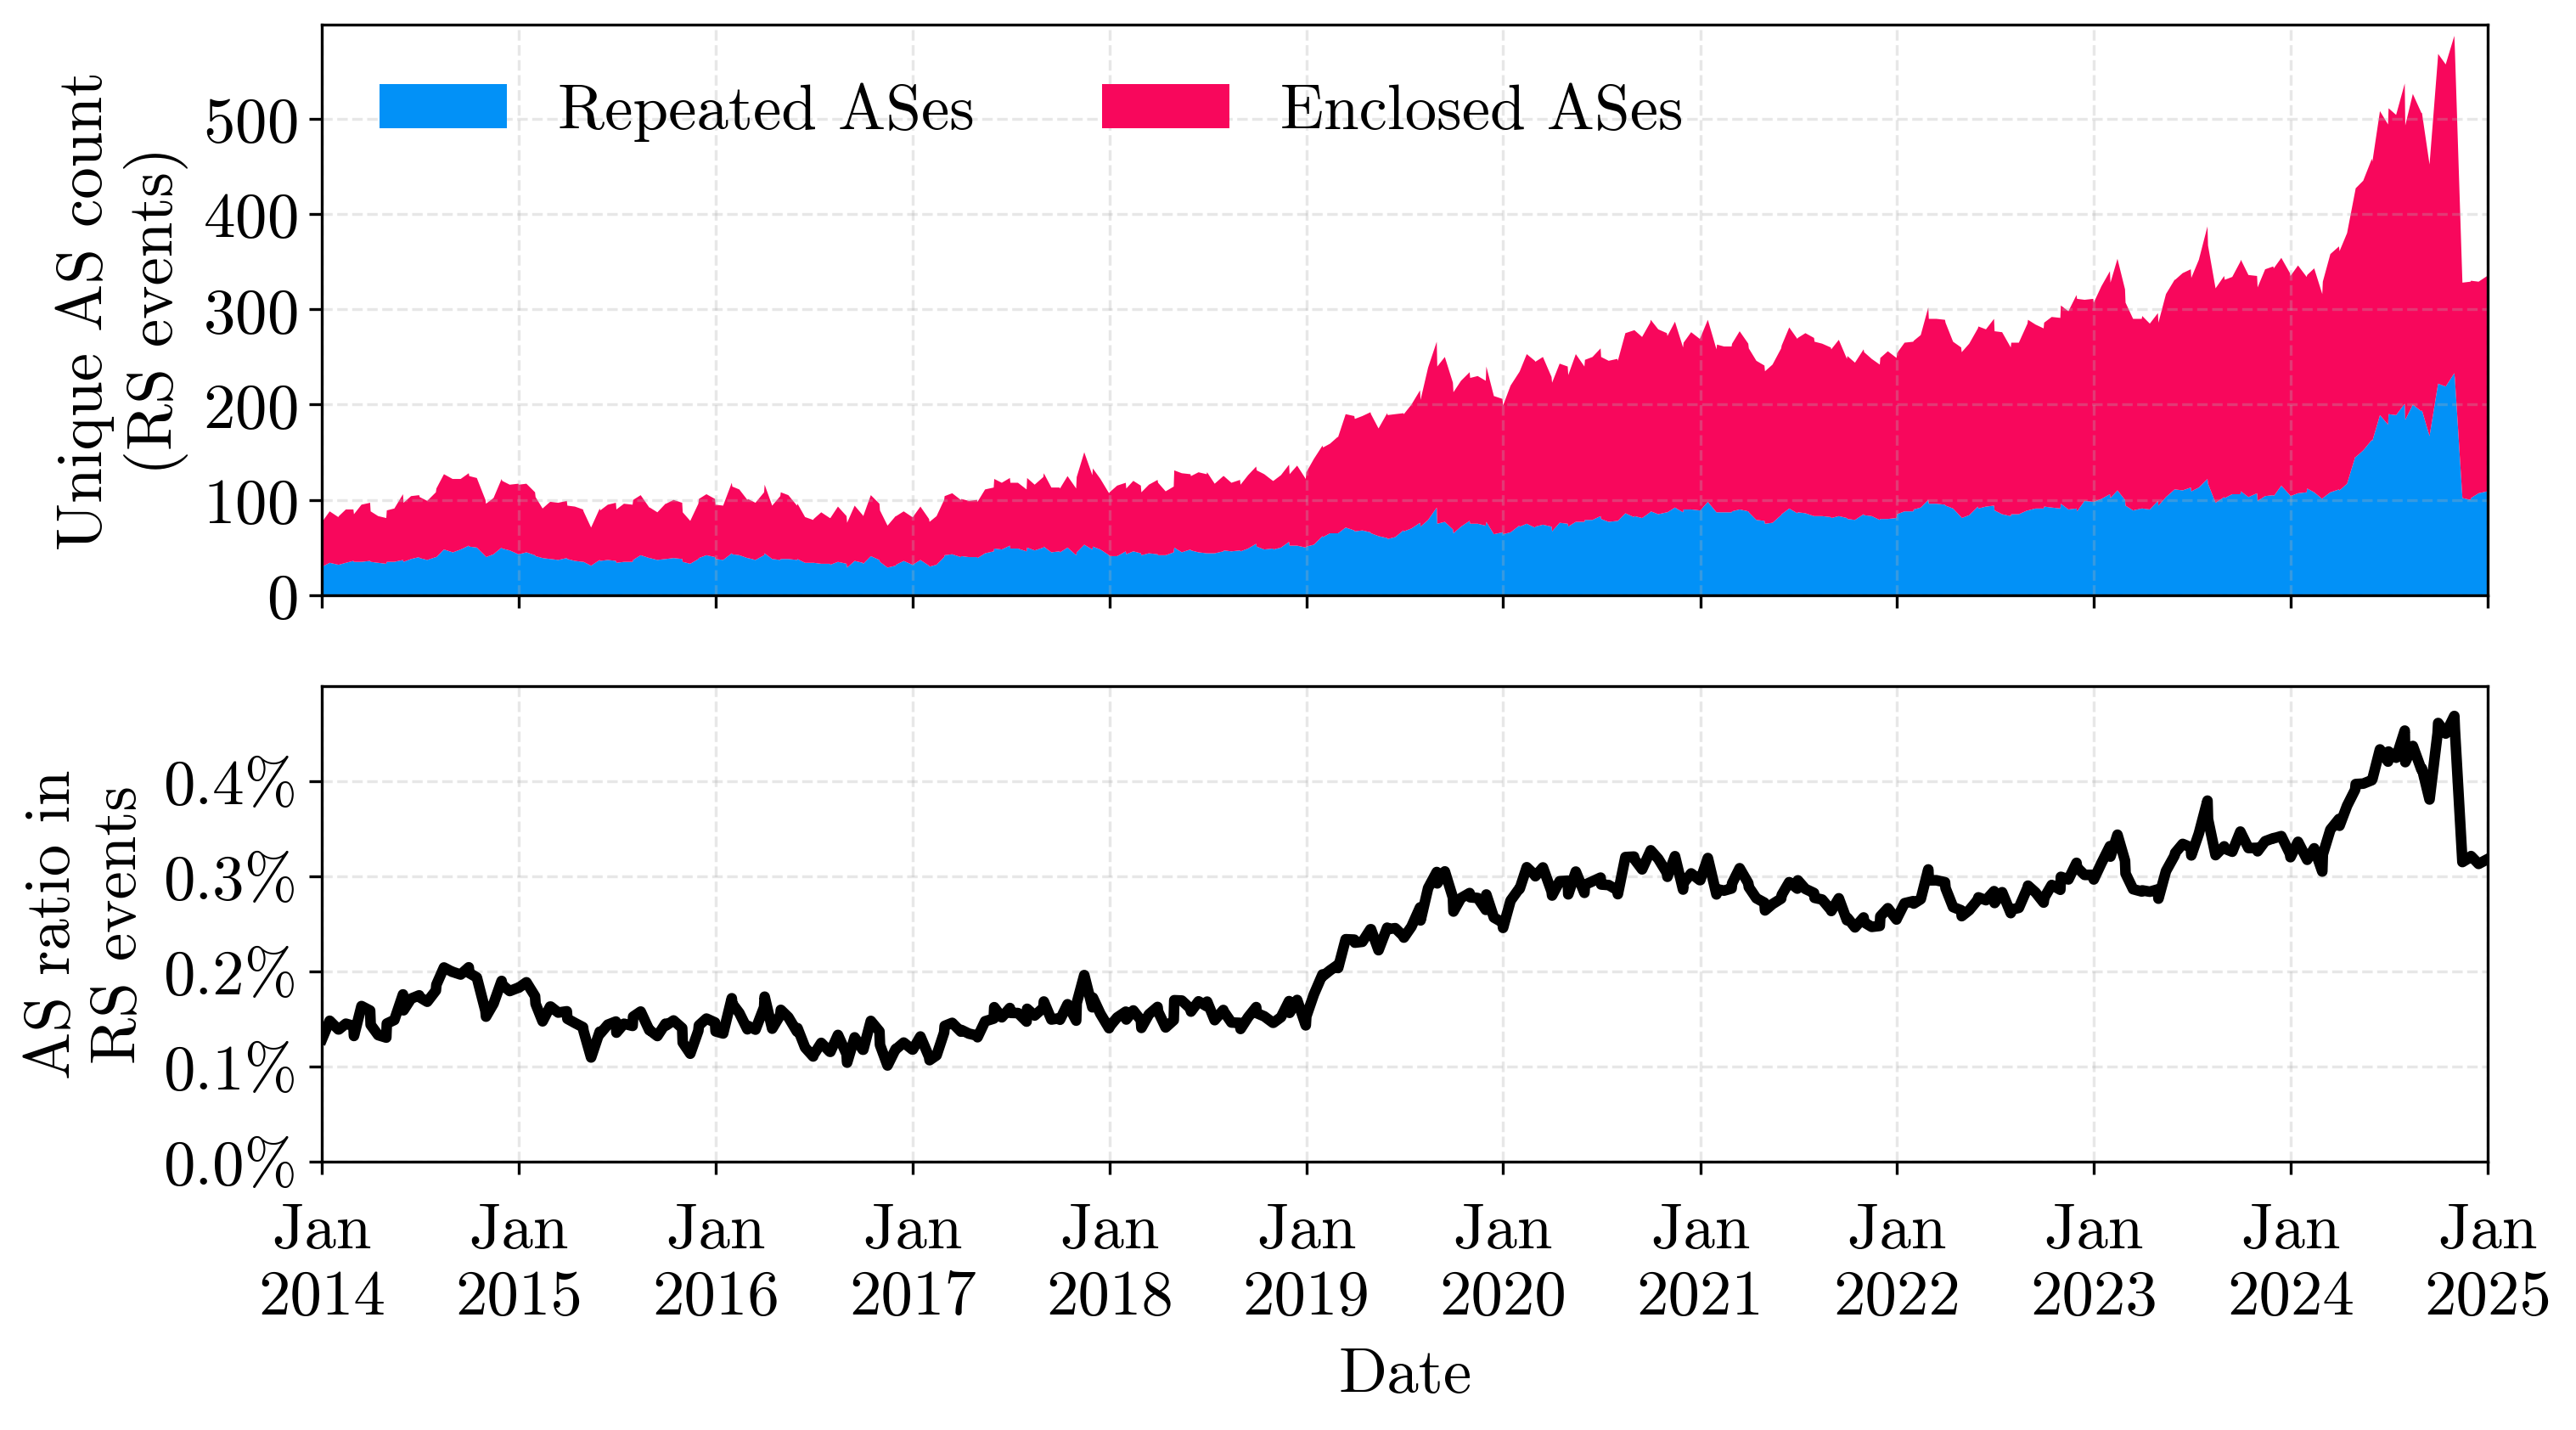

Saved: /home/savymik/Documents/as-repetition/figures/temporal_analysis/c_as_composition.pdf


In [35]:

c = load_daily(
    RS_STATS,
    ["date", "introducing_ases", "appearing_ases", "combined_ratio"],
)

fig, top, bottom = axes_pair()

top.stackplot(
    c.date,
    c.introducing_ases,
    c.appearing_ases,
    colors=[BLUE, RED],
    labels=["Repeated ASes", "Enclosed ASes"],
    alpha=1,
)
top.yaxis.set_major_locator(FixedLocator([0, 100, 200, 300, 400, 500, 600, 700, 800]))
top.set_ylabel("Unique AS count\n(RS events)")
top.legend(frameon=False, ncol=2, loc="upper left")

bottom.plot(c.date, c.combined_ratio, color=BLACK, linewidth=LINEWIDTH)
bottom.set_ylim(0, 0.50)
bottom.yaxis.set_major_locator(FixedLocator([0, 0.1, 0.2, 0.3, 0.4]))
bottom.yaxis.set_major_formatter(FuncFormatter(pct1))
bottom.set_ylabel("AS ratio in\nRS events")

save(fig, "c_as_composition.pdf")


### (d) Non-cons origin ASes and repeated origin ASes

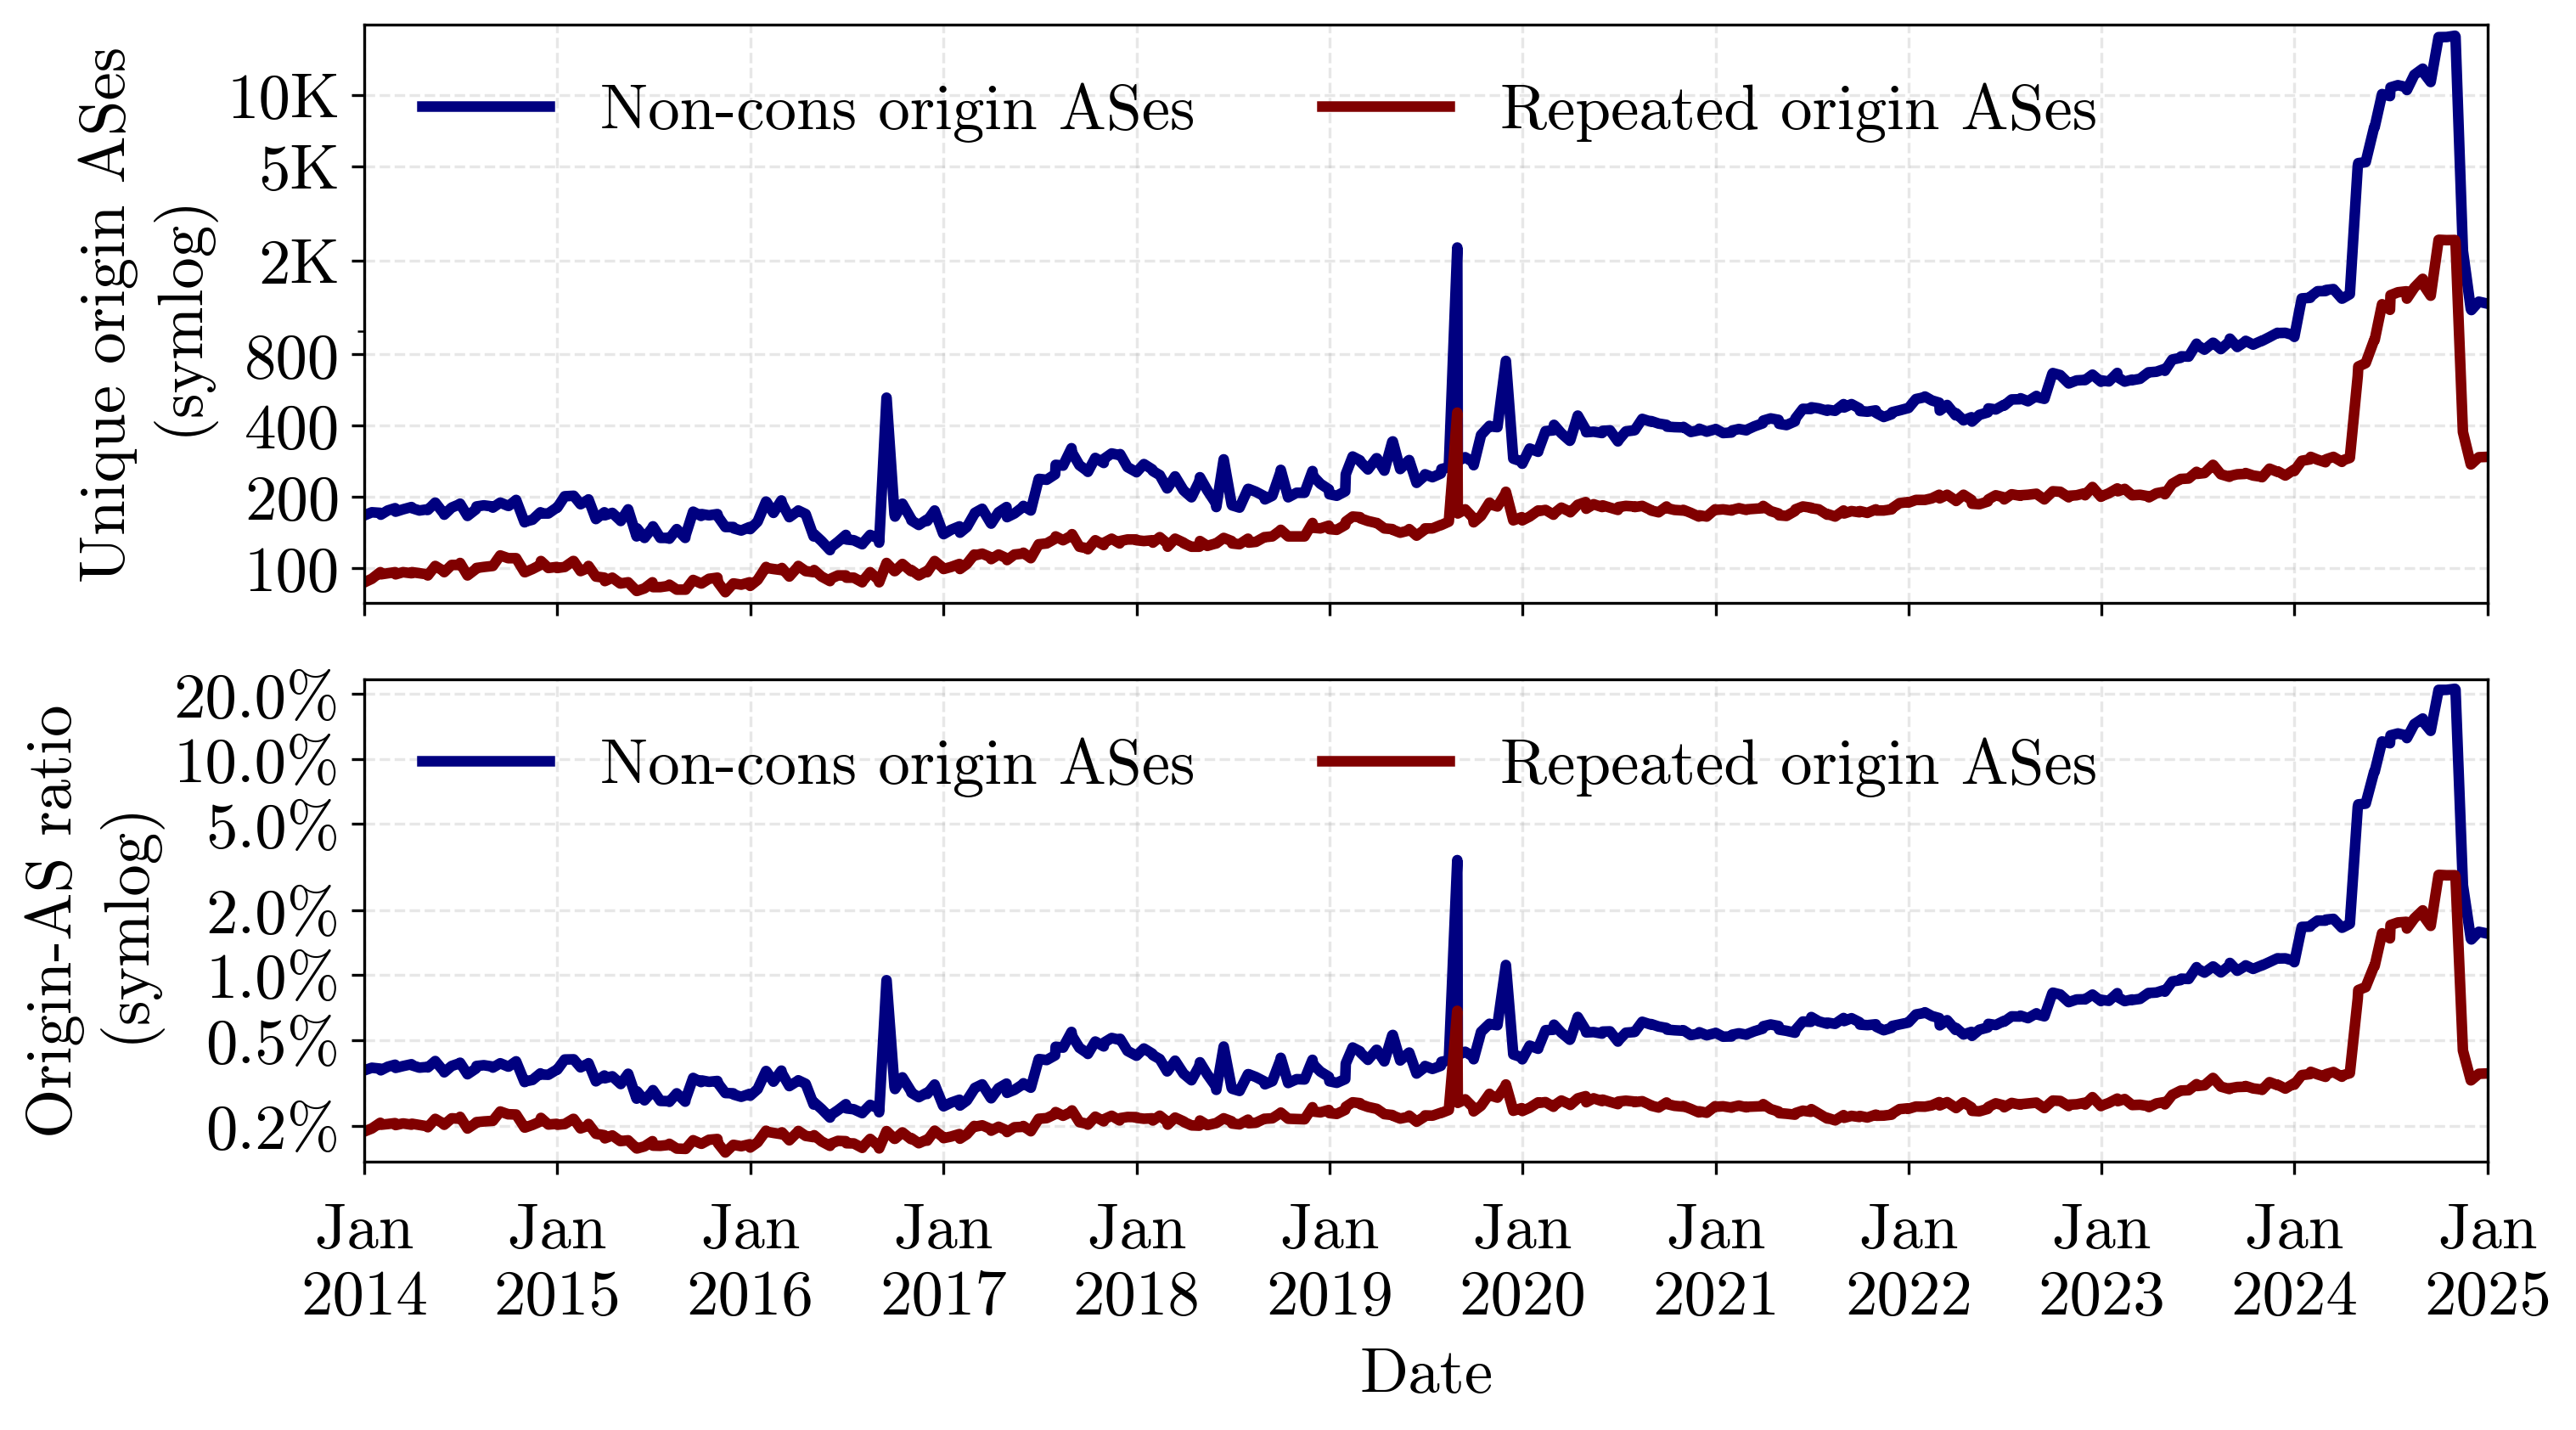

Saved: /home/savymik/Documents/as-repetition/figures/temporal_analysis/d_origin_ases.pdf


In [36]:

d = load_daily(
    ORIGIN_STATS,
    [
        "date", "raw_unique_origin_ases", "filtered_unique_origin_ases",
        "filtered_unique_origin_repeating_ases", "noncons_origin_as_rate_pct",
        "origin_repetition_as_rate_pct",
    ],
)

if (d.filtered_unique_origin_repeating_ases > d.filtered_unique_origin_ases).any():
    raise ValueError("Repeated origin-AS count exceeds non-cons origin-AS count")

if (d.origin_repetition_as_rate_pct > d.noncons_origin_as_rate_pct).any():
    raise ValueError("Repeated origin-AS ratio exceeds non-cons origin-AS ratio")

fig, top, bottom = axes_pair()

top.plot(
    d.date, d.filtered_unique_origin_ases,
    color="navy", linewidth=LINEWIDTH, label="Non-cons origin ASes",
)
top.plot(
    d.date, d.filtered_unique_origin_repeating_ases,
    color="maroon", linewidth=LINEWIDTH, label="Repeated origin ASes",
)
top.set_yscale("symlog", linthresh=10)
top.yaxis.set_major_formatter(FuncFormatter(human_k))

count_max = max(d.filtered_unique_origin_ases.max(), d.filtered_unique_origin_repeating_ases.max())
top.yaxis.set_major_locator(FixedLocator([
    x for x in [0, 10, 20, 50, 100, 200, 400, 800, 2000, 5000, 10000, 20000, 50000]
    if x <= count_max * 1.10
]))
top.set_ylabel("Unique origin ASes\n(symlog)")
top.legend(frameon=False, ncol=2, loc="upper left")

bottom.plot(
    d.date, d.noncons_origin_as_rate_pct,
    color="navy", linewidth=LINEWIDTH, label="Non-cons origin ASes",
)
bottom.plot(
    d.date, d.origin_repetition_as_rate_pct,
    color="maroon", linewidth=LINEWIDTH, label="Repeated origin ASes",
)
bottom.set_yscale("symlog", linthresh=0.1)
bottom.yaxis.set_major_formatter(FuncFormatter(pct1))

rate_max = max(d.noncons_origin_as_rate_pct.max(), d.origin_repetition_as_rate_pct.max())
bottom.yaxis.set_major_locator(FixedLocator([
    x for x in [0, 0.1, 0.2, 0.5, 1, 2, 5, 10, 20, 50]
    if x <= rate_max * 1.15
]))
bottom.set_ylabel("Origin-AS ratio\n(symlog)")
bottom.legend(frameon=False, ncol=2, loc="upper left")

save(fig, "d_origin_ases.pdf")


### Recurrence of Repetition Segments

We measure RS recurrence by counting the distinct sampled days on which each RS appears to assess whether these patterns are consistent with the temporary nature of BGP poisoning used for traffic engineering. We reproduce this analysis using the filtered repetition segment dataset.

Counting RS observed days:   0%|          | 0/396 [00:00<?, ?it/s]

Unique RSs: 7,046
Median observed days: 5.0
Maximum observed days: 394


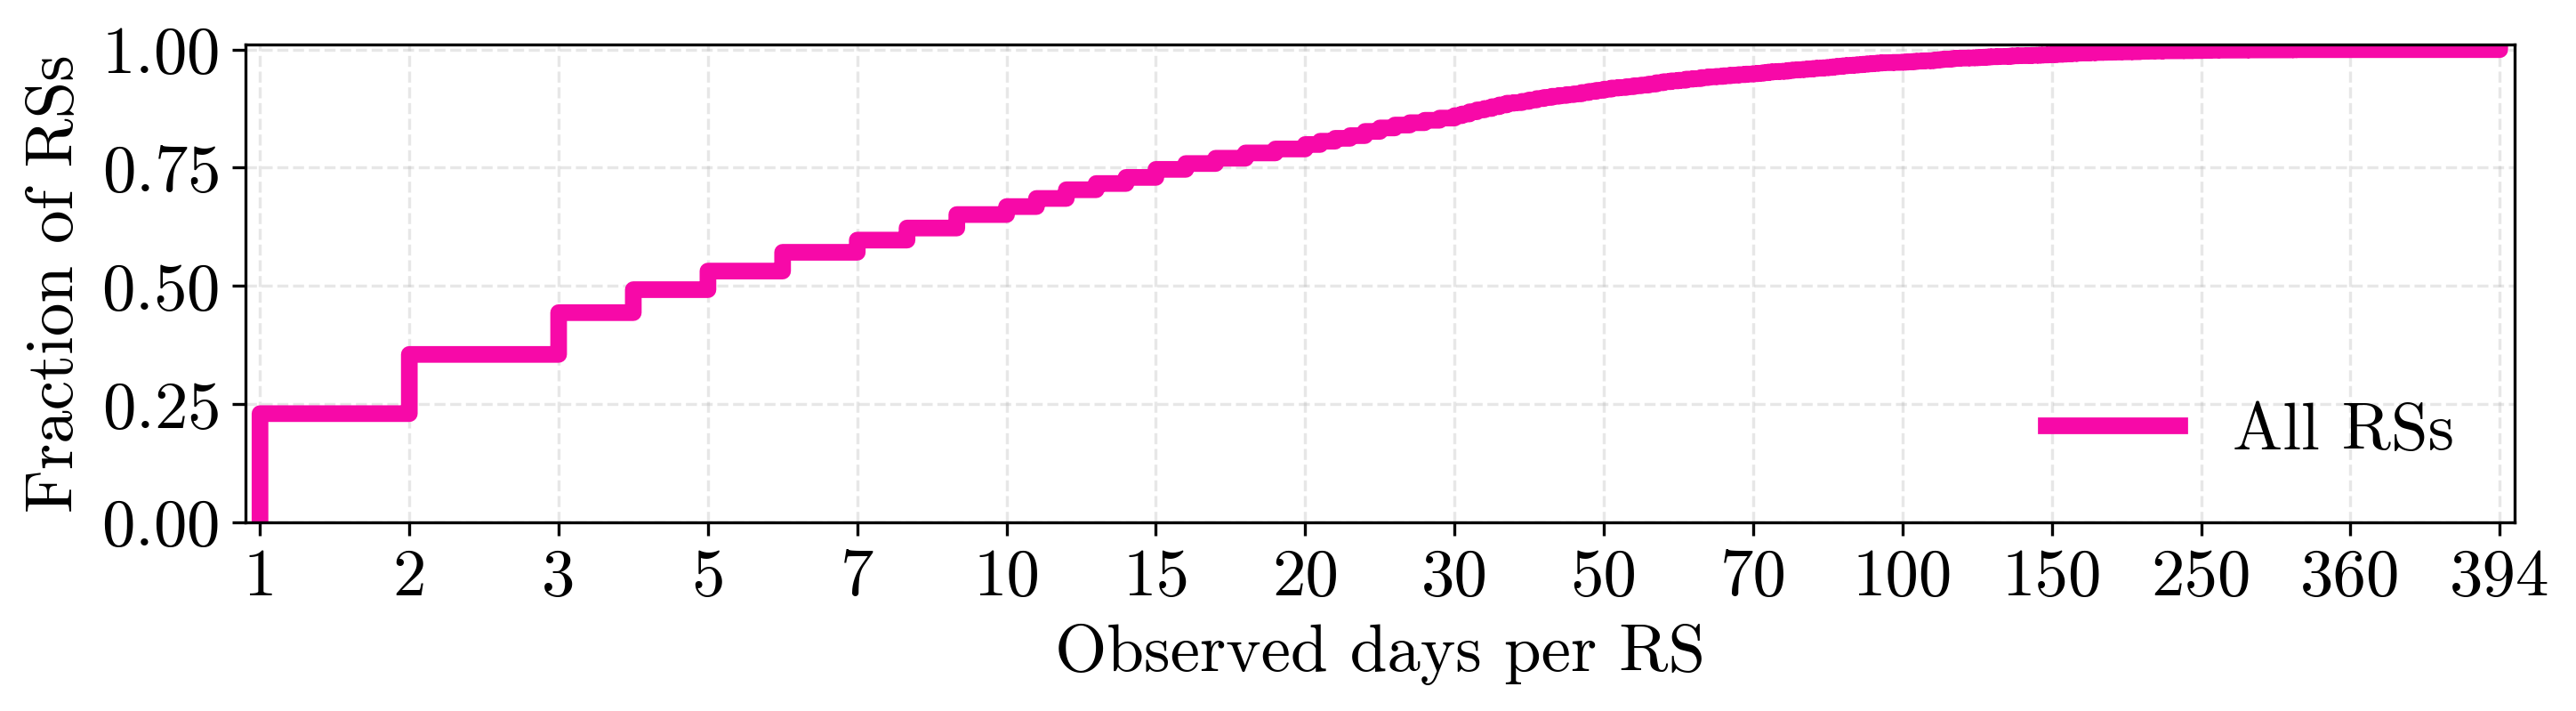

In [41]:

from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

ROOT = Path.cwd().resolve()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent

SEGMENTS = ROOT / "data/prefix.aspth.parquet/poisoning/segments.filtered"
FIGURES = ROOT / "figures/recurrence"
FIGURES.mkdir(parents=True, exist_ok=True)

FILES = sorted(SEGMENTS.glob("segments.*.parquet"))
EXPECTED = 396
TICKS = [1, 2, 3, 5, 7, 10, 15, 20, 30, 50, 70, 100, 150, 250, 360]

if len(FILES) != EXPECTED:
    raise ValueError(f"Expected {EXPECTED} segment files, found {len(FILES)}")

rows = []

for path in tqdm(FILES, desc="Counting RS observed days"):
    match = re.search(r"(\d{4})[-.](\d{2})[-.](\d{2})", path.name)
    if not match:
        raise ValueError(f"Cannot extract date from {path.name}")

    date = pd.Timestamp("-".join(match.groups()))
    df = pd.read_parquet(path, columns=["poisoned_segment"])
    segments = df["poisoned_segment"].dropna().unique()

    rows.extend((date, segment) for segment in segments)

rs_days = pd.DataFrame(rows, columns=["date", "segment"]).drop_duplicates()

if rs_days.date.nunique() > EXPECTED:
    raise ValueError("Unexpected number of sampled dates")

observed_days = (
    rs_days.groupby("segment")["date"]
    .nunique()
    .sort_values()
    .to_numpy()
)

if len(observed_days) == 0:
    raise ValueError("No repetition segments found")

print(f"Unique RSs: {len(observed_days):,}")
print(f"Median observed days: {np.median(observed_days):.1f}")
print(f"Maximum observed days: {observed_days.max():,}")

x = observed_days
y = np.arange(1, len(x) + 1) / len(x)

ticks = [tick for tick in TICKS if tick <= x.max()]
if x.max() > ticks[-1]:
    ticks.append(int(x.max()))

positions = np.arange(len(ticks))
x_transformed = np.interp(x, ticks, positions)

fig, ax = plt.subplots(figsize=(10, 3), dpi=300)

ax.step(
    x_transformed, y,
    where="post", linewidth=4.5,
    color="#F709A8", label="All RSs",
)

ax.set_xticks(positions, [str(tick) for tick in ticks])
ax.set_xlim(-0.1, len(ticks) - 0.9)
ax.set_ylim(0, 1.01)
ax.set_yticks([0, 0.25, 0.50, 0.75, 1.00])
ax.set_xlabel("Observed days per RS")
ax.set_ylabel("Fraction of RSs")
ax.grid(True, which="major", linestyle="--", alpha=0.30)
ax.legend(frameon=False, loc="lower right")

plt.tight_layout()
fig.savefig(FIGURES / "observed_days.filtered.pdf", bbox_inches="tight", pad_inches=0.04)
plt.show()


In [42]:
print(f"Unique RSs: {len(observed_days):,}")
print(f"Median observed days: {np.median(observed_days):.1f}")
print(f"Mean observed days: {np.mean(observed_days):.2f}")
print(f"Maximum observed days: {np.max(observed_days):,}")
print(f"Observed once: {(observed_days == 1).sum():,} ({(observed_days == 1).mean():.2%})")
print(f"Observed >10 days: {(observed_days > 10).sum():,} ({(observed_days > 10).mean():.2%})")

Unique RSs: 7,046
Median observed days: 5.0
Mean observed days: 16.04
Maximum observed days: 394
Observed once: 1,616 (22.93%)
Observed >10 days: 2,342 (33.24%)


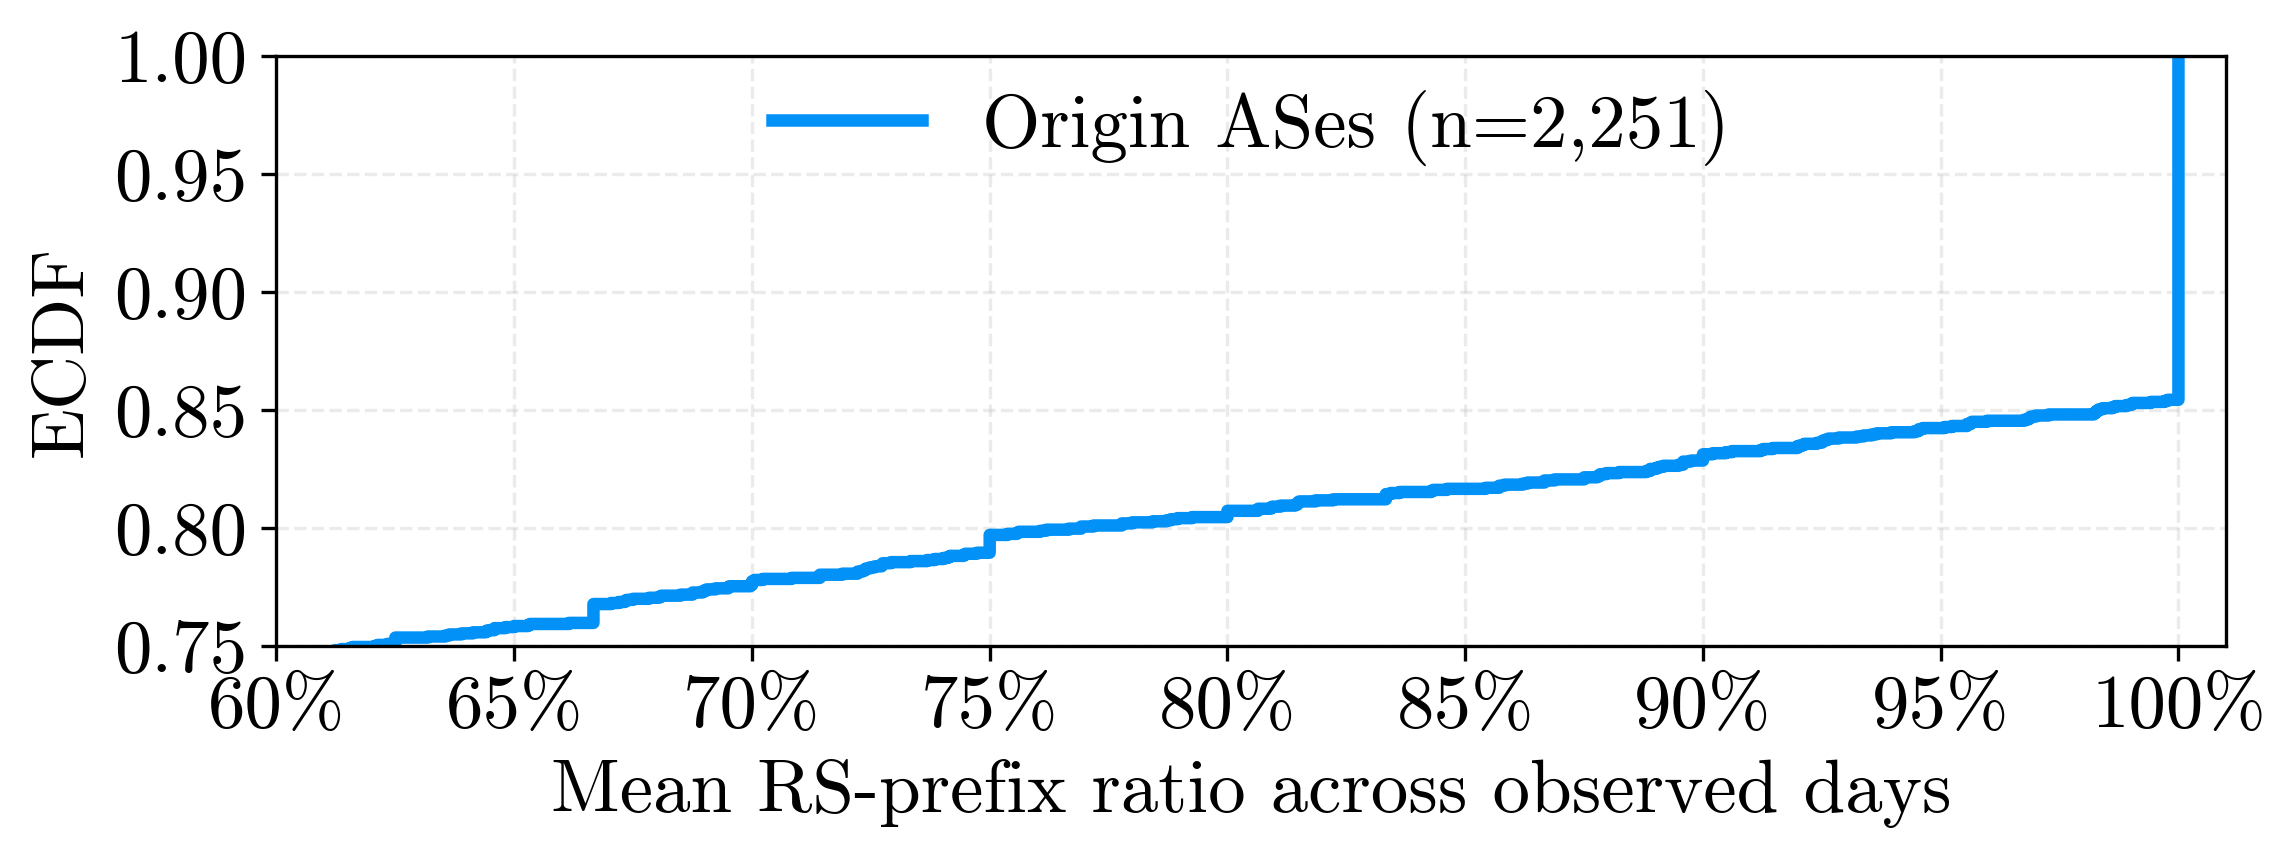

Origin ASes: 2,251 ASes
Median ratio: 25.00%
75th percentile: 62.10%
ASes at 100%: 328


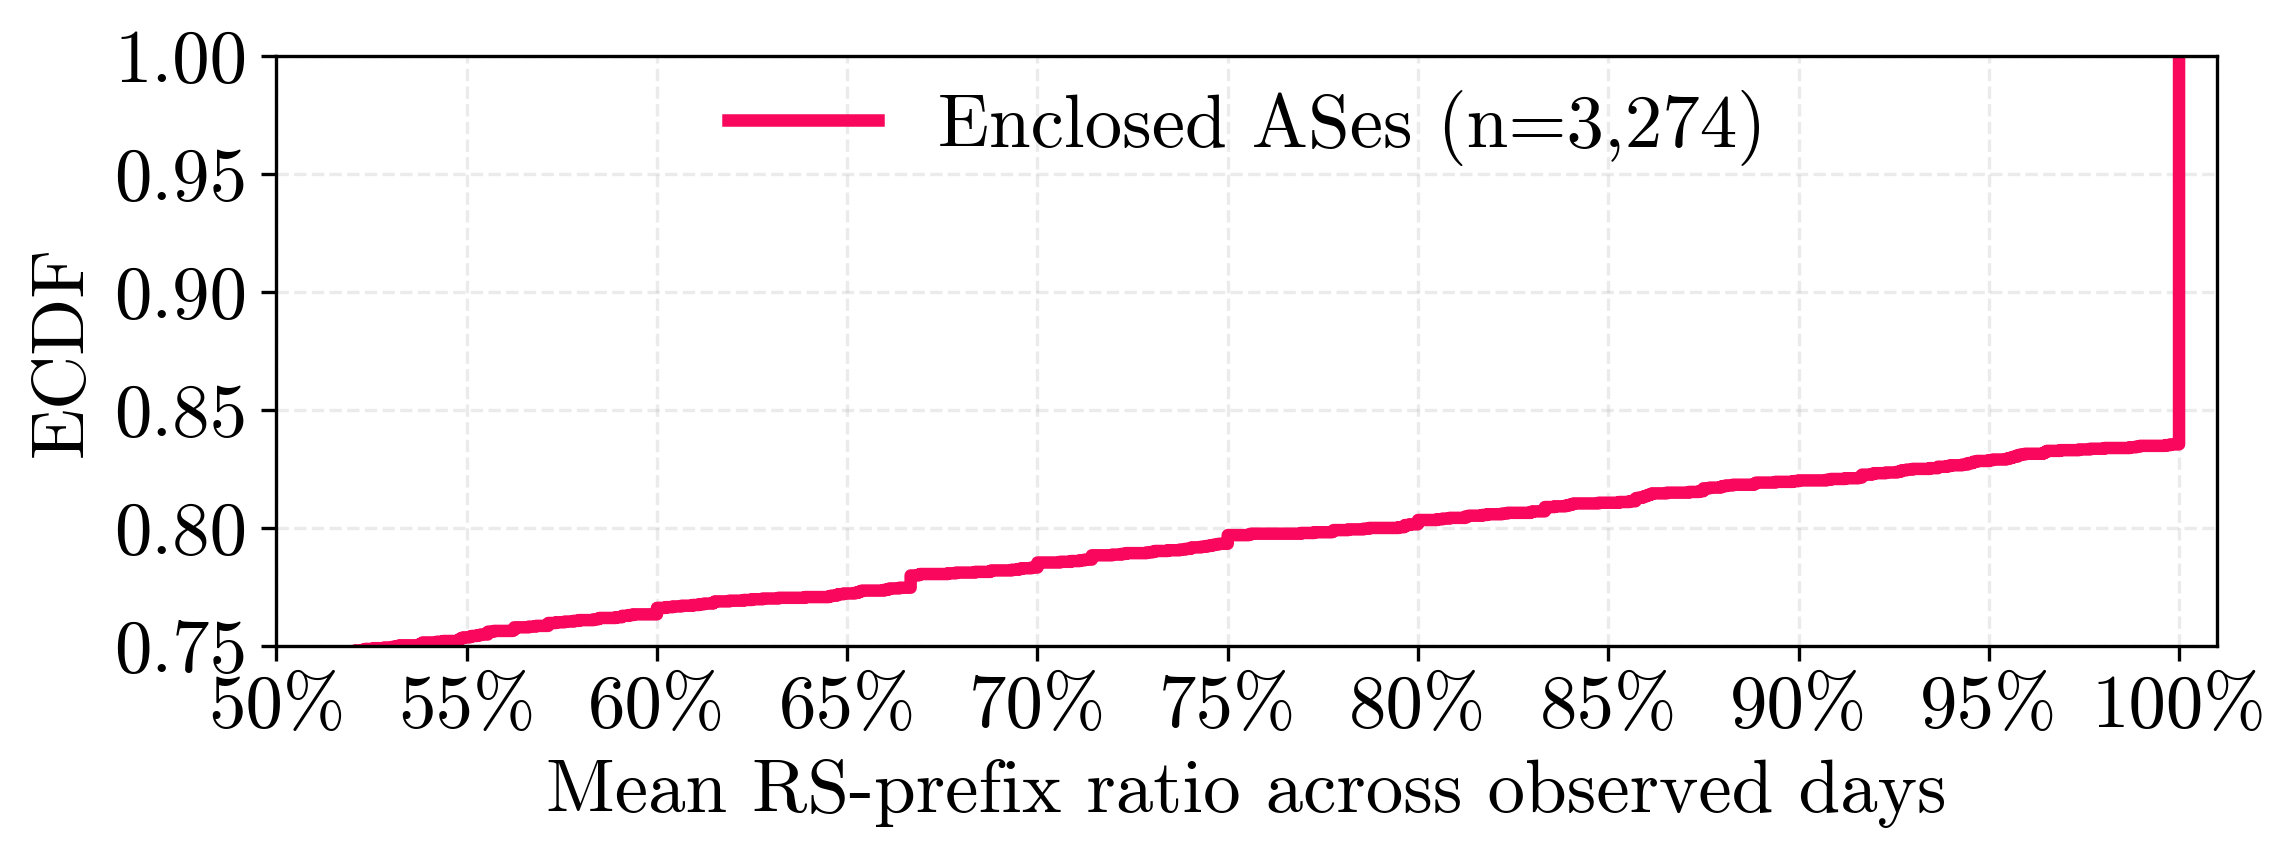

Enclosed ASes: 3,274 ASes
Median ratio: 11.36%
75th percentile: 53.22%
ASes at 100%: 539


In [48]:

INPUT = ROOT / "data/prefix_ratio/rs_prefix_ratio.asn_day.parquet"
OUT = ROOT / "figures/prefix_ratio"
OUT.mkdir(parents=True, exist_ok=True)

daily = pd.read_parquet(
    INPUT, columns=["date", "role", "asn", "rs_prefix_ratio_pct"]
)

if daily.duplicated(["date", "role", "asn"]).any():
    raise ValueError("Duplicate AS-day observations")

if not daily["rs_prefix_ratio_pct"].between(0, 100).all():
    raise ValueError("Invalid daily RS-prefix ratios")

profiles = (
    daily.groupby(["role", "asn"], as_index=False)
    .agg(mean_ratio_pct=("rs_prefix_ratio_pct", "mean"))
)

panels = {
    "origin": ("Origin ASes", BLUE, 60, "rs_prefix_ratio_origin_ases_ecdf_top25.pdf"),
    "enclosed": ("Enclosed ASes", RED, 50, "rs_prefix_ratio_enclosed_ases_ecdf_top25.pdf"),
}

for role, (label, color, xmin, filename) in panels.items():
    values = np.sort(
        profiles.loc[profiles.role == role, "mean_ratio_pct"].to_numpy()
    )
    if len(values) == 0:
        raise ValueError(f"No observations for {role}")

    y = np.arange(1, len(values) + 1) / len(values)

    fig, ax = plt.subplots(figsize=(8, 3.2), dpi=300)
    ax.step(
        values, y, where="post", color=color, linewidth=3,
        label=f"{label} (n={len(values):,})",
    )

    ax.set_xlim(xmin, 101)
    ax.set_ylim(0.75, 1.00)
    ax.set_xticks(np.arange(xmin, 101, 5))
    ax.set_yticks(np.arange(0.75, 1.001, 0.05))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:.0f}%"))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{y:.2f}"))
    ax.set_xlabel("Mean RS-prefix ratio across observed days")
    ax.set_ylabel("ECDF")
    ax.legend(loc="lower center", bbox_to_anchor=(0.5, 0.70), frameon=False)
    ax.grid(True, linestyle="--", linewidth=0.8, alpha=0.25)

    fig.tight_layout()
    fig.savefig(OUT / filename, bbox_inches="tight", pad_inches=0.08)
    plt.show()

    print(f"{label}: {len(values):,} ASes")
    print(f"Median ratio: {np.median(values):.2f}%")
    print(f"75th percentile: {np.percentile(values, 75):.2f}%")
    print(f"ASes at 100%: {np.isclose(values, 100).sum():,}")


In [50]:
original = pd.read_parquet(
    ROOT / "data/prefix_ratio/rs_prefix_ratio.asn_profiles.parquet",
    columns=["role", "asn", "mean_ratio_pct"],
)

comparison = profiles.merge(
    original,
    on=["role", "asn"],
    how="outer",
    validate="one_to_one",
    suffixes=("_new", "_original"),
    indicator=True,
)

assert (comparison["_merge"] == "both").all()
assert np.allclose(
    comparison["mean_ratio_pct_new"],
    comparison["mean_ratio_pct_original"],
    rtol=0,
    atol=1e-9,
)

print("Per-AS mean ratios match the original analysis.")

Per-AS mean ratios match the original analysis.


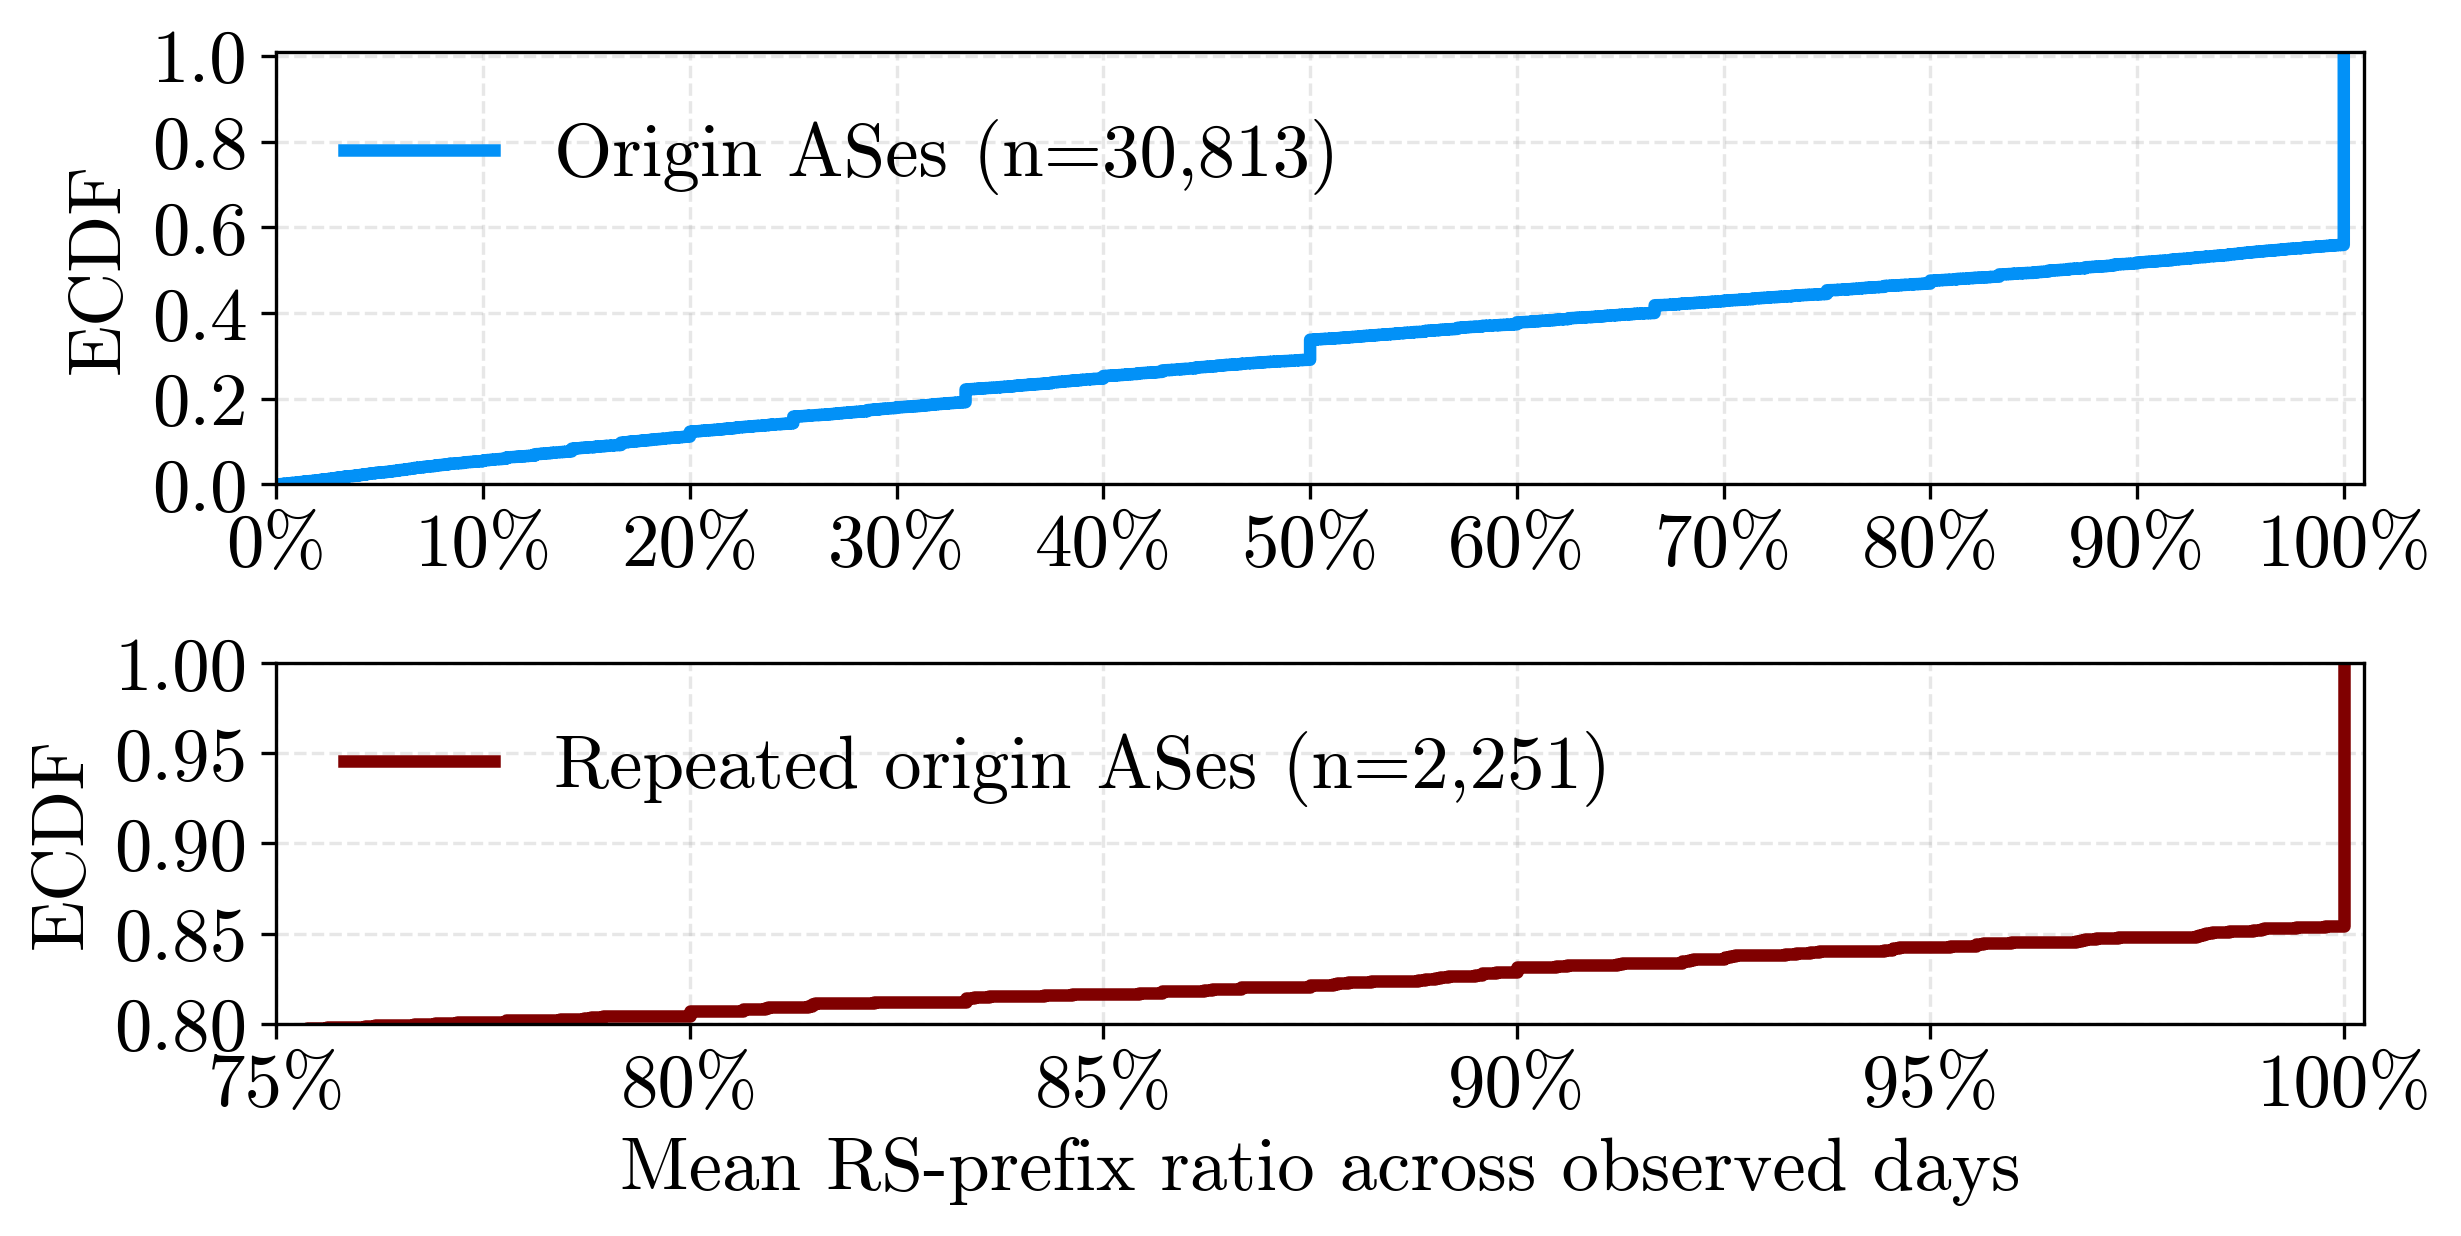

Origin ASes: 30,813 ASes; median=86.11%; at 100%=13,589
Repeated origin ASes: 2,251 ASes; median=25.00%; at 100%=328


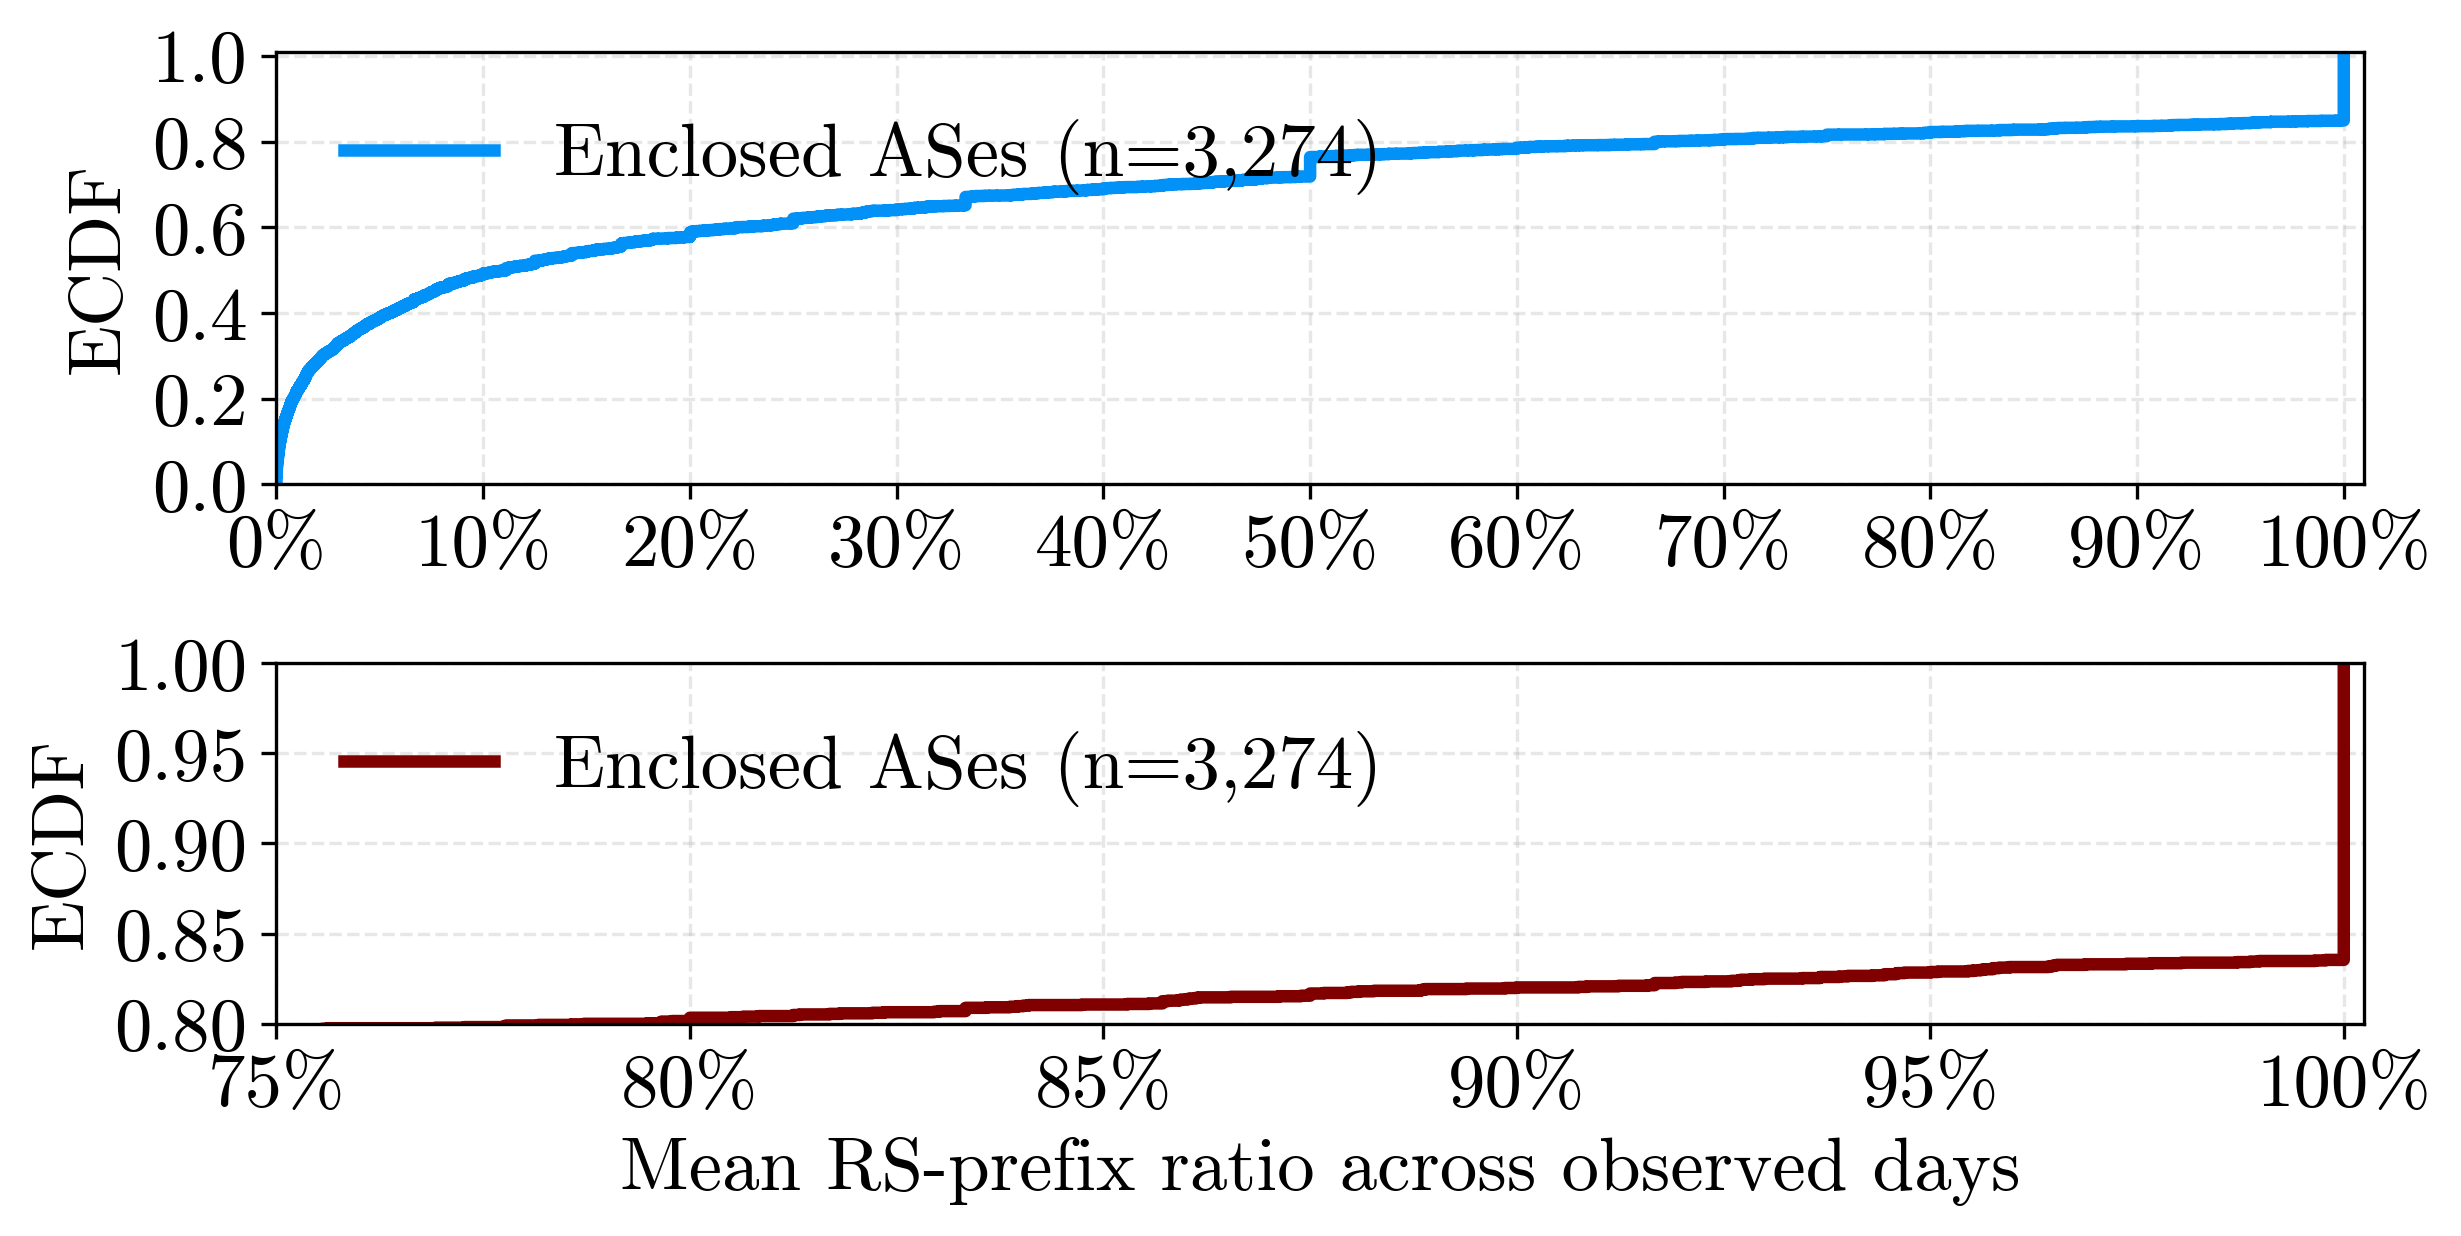

Enclosed ASes: 3,274 ASes; median=11.11%; at 100%=493
Enclosed ASes: 3,274 ASes; median=11.36%; at 100%=539


In [59]:

from matplotlib.ticker import FuncFormatter

PREFIX_RATIO = ROOT / "data/prefix_ratio"
OUT = ROOT / "figures/prefix_ratio"
OUT.mkdir(parents=True, exist_ok=True)

original = pd.read_parquet(
    PREFIX_RATIO / "rs_prefix_ratio.asn_day.filtered.parquet",
    columns=["date", "rs_class", "role", "asn", "rs_prefix_ratio_pct"],
)

revised = pd.read_parquet(
    PREFIX_RATIO / "rs_prefix_ratio.asn_profiles.parquet",
    columns=["role", "asn", "mean_ratio_pct"],
)

original["date"] = pd.to_datetime(original["date"])

if original.duplicated(["date", "rs_class", "role", "asn"]).any():
    raise ValueError("Duplicate original AS-day-class records")

if revised.duplicated(["role", "asn"]).any():
    raise ValueError("Duplicate revised AS profiles")

original_profiles = (
    original.groupby(["role", "asn"], as_index=False)
    .agg(mean_ratio_pct=("rs_prefix_ratio_pct", "mean"))
)

def ecdf(values):
    values = np.sort(np.asarray(values, dtype=float))
    if not len(values) or not np.isfinite(values).all():
        raise ValueError("Empty or non-finite ratio values")
    if ((values < 0) | (values > 100)).any():
        raise ValueError("RS-prefix ratios outside [0, 100]")
    return values, np.arange(1, len(values) + 1) / len(values)

def plot_ratio_comparison(original_role, revised_role, labels, filename):
    original_values = original_profiles.loc[
        original_profiles.role == original_role, "mean_ratio_pct"
    ].to_numpy()
    revised_values = revised.loc[
        revised.role == revised_role, "mean_ratio_pct"
    ].to_numpy()

    fig, (top, bottom) = plt.subplots(
        2, 1, figsize=(8, 4), dpi=300,
        gridspec_kw={"height_ratios": [1.2, 1.0]},
    )

    for ax, values, label, color, is_revised in [
        (top, original_values, labels[0], BLUE, False),
        (bottom, revised_values, labels[1], "maroon", True),
    ]:
        x, y = ecdf(values)
        ax.step(
            x, y, where="post", linewidth=LINEWIDTH,
            color=color, label=f"{label} (n={len(values):,})",
        )

        xmin = 75 if is_revised else 0
        ax.set_xlim(xmin, 100 + (100 - xmin) * 0.01)
        ax.set_ylim((0.8 if is_revised else 0), (1.0 if is_revised else 1.01))
        ax.set_xticks(np.arange(xmin, 101, 5 if is_revised else 10))
        ax.set_yticks(
            np.arange(0.8, 1.001, 0.05) if is_revised
            else np.arange(0, 1.01, 0.2)
        )
        ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}%"))
        ax.yaxis.set_major_formatter(FuncFormatter(
            (lambda v, _: f"{v:.2f}") if is_revised
            else (lambda v, _: f"{v:.1f}")
        ))
        ax.set_ylabel("ECDF")
        ax.grid(True, which="major", linestyle="--", alpha=0.30)
        ax.minorticks_off()
        ax.legend(frameon=False, loc="upper left")

    bottom.set_xlabel("Mean RS-prefix ratio across observed days")
    fig.subplots_adjust(
        left=0.11, right=0.98, top=0.98, bottom=0.17, hspace=0.45
    )
    fig.savefig(OUT / filename, dpi=300, bbox_inches="tight", pad_inches=0.04)
    plt.show()

    for label, values in [(labels[0], original_values), (labels[1], revised_values)]:
        print(
            f"{label}: {len(values):,} ASes; "
            f"median={np.median(values):.2f}%; "
            f"at 100%={np.isclose(values, 100, atol=1e-9, rtol=0).sum():,}"
        )

plot_ratio_comparison(
    "origin", "origin",
    ("Origin ASes", "Repeated origin ASes"),
    "origin_ases_original_vs_revised.pdf",
)

plot_ratio_comparison(
    "appearing", "enclosed",
    ("Enclosed ASes", "Enclosed ASes"),
    "enclosed_ases_original_vs_revised.pdf",
)


### Sibling ASes

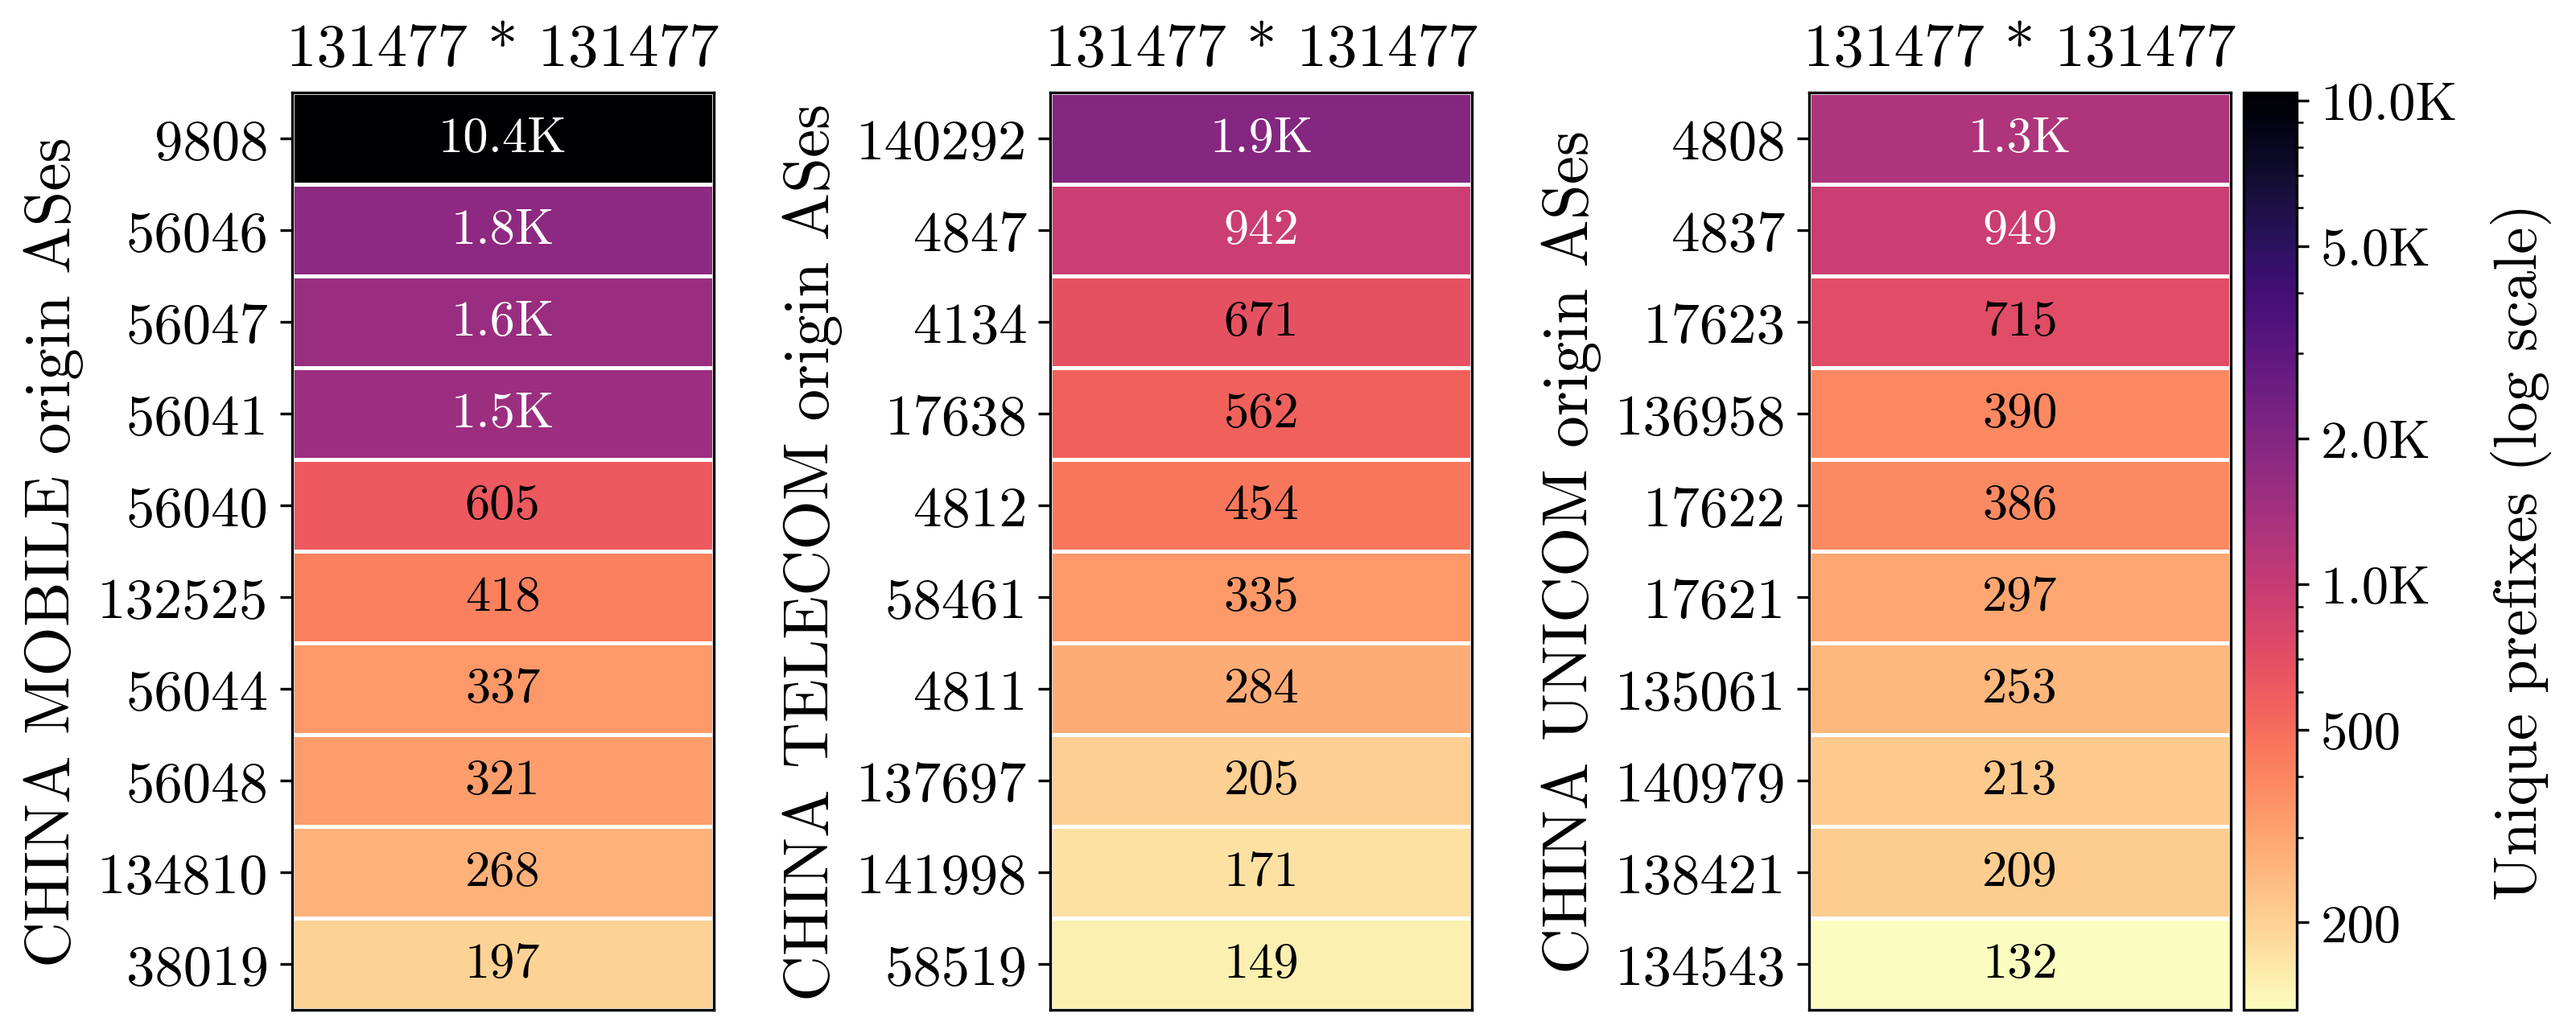

Target RS: 131477 65511 140096 131477
Organizations: 440
Origin ASes: 586
Unique prefixes: 55,744
Top organizations: ['CHINA MOBILE', 'CHINA TELECOM', 'CHINA UNICOM']
Saved: /home/savymik/Documents/as-repetition/figures/sibling_ases/rs_131477_top3_orgs_top10_origin_ases.pdf


In [65]:
import re
from matplotlib.colors import LogNorm

INPUT = ROOT / "data/sibling_ases/dominant_rs_org_prefixes.parquet"
OUT = ROOT / "figures/sibling_ases"
OUT.mkdir(parents=True, exist_ok=True)

TARGET_RS = "131477 65511 140096 131477"

df = pd.read_parquet(
    INPUT,
    columns=["org", "origin_as", "prefix", "poisoned_segment"],
)

required = {"org", "origin_as", "prefix", "poisoned_segment"}
if missing := required - set(df.columns):
    raise ValueError(f"Missing columns: {sorted(missing)}")

df["org"] = df["org"].astype(str).str.strip()
df["origin_as"] = pd.to_numeric(df["origin_as"]).astype("int64")
df["poisoned_segment"] = df["poisoned_segment"].astype(str).str.strip()

df = df.loc[df["poisoned_segment"] == TARGET_RS].copy()

if df.empty:
    raise ValueError("No observations for the target RS")

org_counts = (
    df.groupby("org")["prefix"]
    .nunique()
    .sort_values(ascending=False)
)

top_orgs = org_counts.head(3).index.tolist()

if len(top_orgs) != 3:
    raise ValueError("Expected three organizations")

heat = (
    df.loc[df["org"].isin(top_orgs)]
    .groupby(["org", "origin_as"], as_index=False)
    .agg(value=("prefix", "nunique"))
)

heat = (
    heat.sort_values(
        ["org", "value", "origin_as"],
        ascending=[True, False, True],
    )
    .groupby("org", group_keys=False)
    .head(10)
)

positive = heat.loc[heat["value"] > 0, "value"]

if positive.empty:
    raise ValueError("No positive heatmap values")

vmin = max(1, float(positive.min()))
vmax = max(1, float(positive.max()))
norm = LogNorm(vmin=vmin, vmax=vmax)


def human(x):
    if x >= 1_000_000:
        return f"{x / 1_000_000:.1f}M"
    if x >= 1_000:
        return f"{x / 1_000:.1f}K"
    return f"{int(x)}"


fig, axes = plt.subplots(1, 3, figsize=(11, 5), dpi=300)

for ax, org in zip(axes, top_orgs):
    sub = (
        heat.loc[heat["org"] == org]
        .sort_values(
            ["value", "origin_as"],
            ascending=[False, True],
        )
        .head(10)
    )

    values = sub[["value"]].to_numpy()
    asns = sub["origin_as"].tolist()

    im = ax.imshow(
        values,
        aspect="auto",
        interpolation="nearest",
        norm=norm,
        cmap="magma_r",
    )

    for y in np.arange(-0.5, len(asns), 1):
        ax.axhline(y, color="white", linewidth=1.2)

    ax.axvline(-0.5, color="white", linewidth=1.2)
    ax.axvline(0.5, color="white", linewidth=1.2)

    for i, value in enumerate(values.flatten()):
        ax.text(
            0, i, human(value),
            ha="center",
            va="center",
            fontsize=15,
            fontweight="bold",
            color="white" if value >= vmax * 0.08 else "black",
        )

    ax.set_title("131477 * 131477", fontsize=18, pad=8)
    ax.set_xticks([])
    ax.set_yticks(range(len(asns)), [str(asn) for asn in asns])

    org_name = re.sub(r"\s+", " ", org)

    ax.set_ylabel(
        f"{org_name} origin ASes",
        fontsize=19,
    )

    ax.tick_params(axis="y", labelsize=17)

fig.subplots_adjust(
    left=0.11,
    right=0.84,
    bottom=0.12,
    top=0.88,
    wspace=0.80,
)

pos = axes[-1].get_position()
cax = fig.add_axes([0.845, pos.y0, 0.020, pos.height])
cbar = fig.colorbar(im, cax=cax)

ticks = [
    base * 10**exp
    for exp in range(
        int(np.floor(np.log10(vmin))),
        int(np.ceil(np.log10(vmax))) + 1,
    )
    for base in (1, 2, 5)
    if vmin <= base * 10**exp <= vmax
]

cbar.set_ticks(ticks)
cbar.ax.set_yticklabels(
    [human(tick) for tick in ticks],
    fontsize=16,
)
cbar.set_label(
    "Unique prefixes (log scale)",
    fontsize=18,
    labelpad=10,
)

pdf = OUT / "rs_131477_top3_orgs_top10_origin_ases.pdf"

fig.savefig(
    pdf,
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.04,
)

plt.show()

print(f"Target RS: {TARGET_RS}")
print(f"Organizations: {df['org'].nunique():,}")
print(f"Origin ASes: {df['origin_as'].nunique():,}")
print(f"Unique prefixes: {df['prefix'].nunique():,}")
print(f"Top organizations: {top_orgs}")
print(f"Saved: {pdf}")

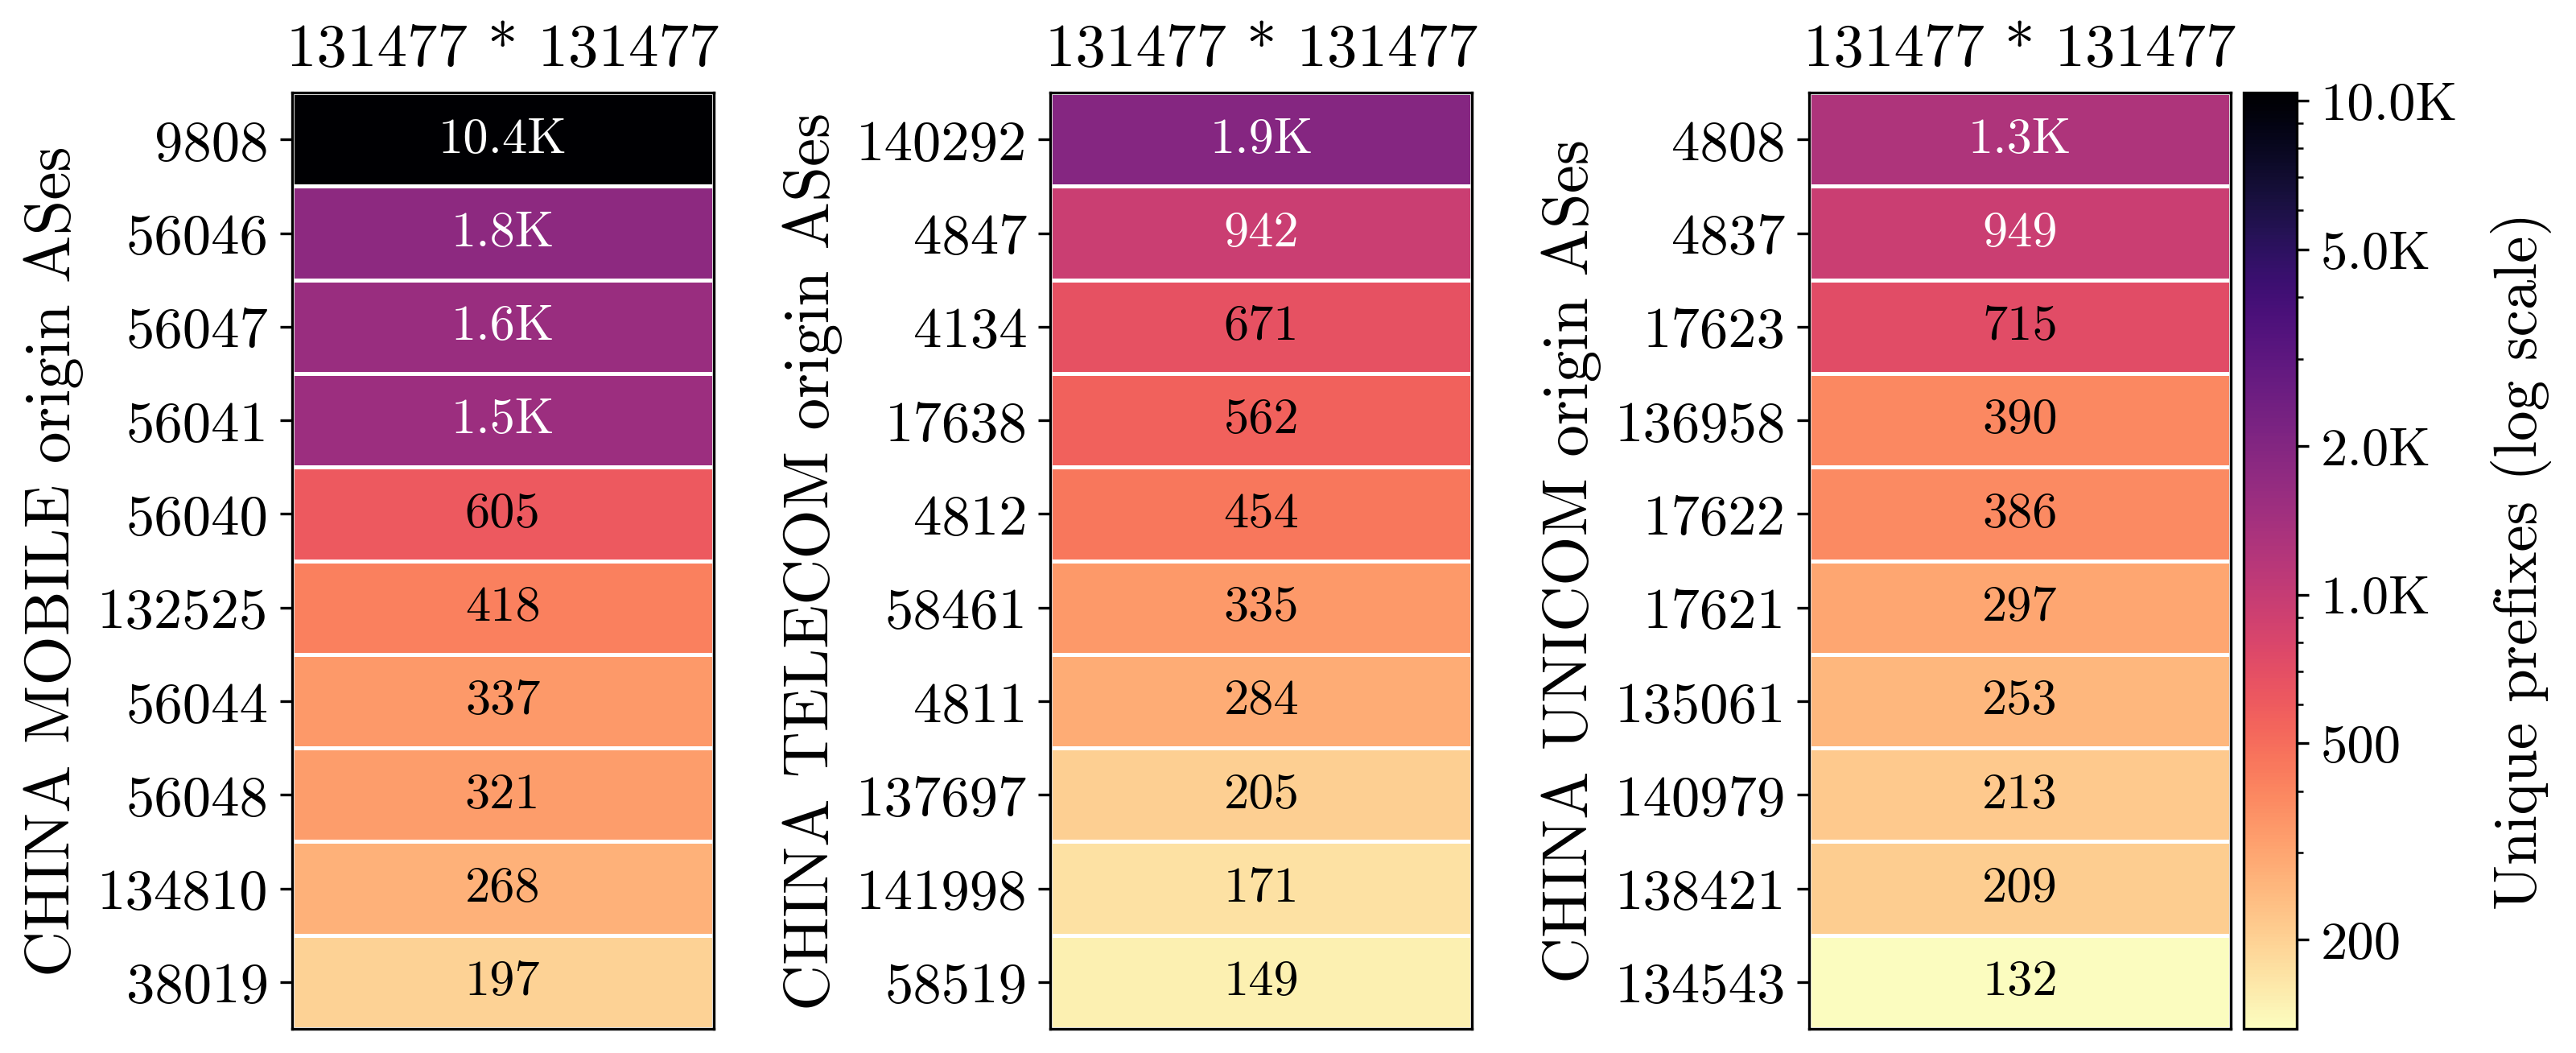


RS: 131477 65511 140096 131477
Unique prefixes: 55,744
Organizations: 440
Origin ASes: 586
Top organizations: ['CHINA MOBILE', 'CHINA TELECOM', 'CHINA UNICOM']
----------------------------------------------------------------------


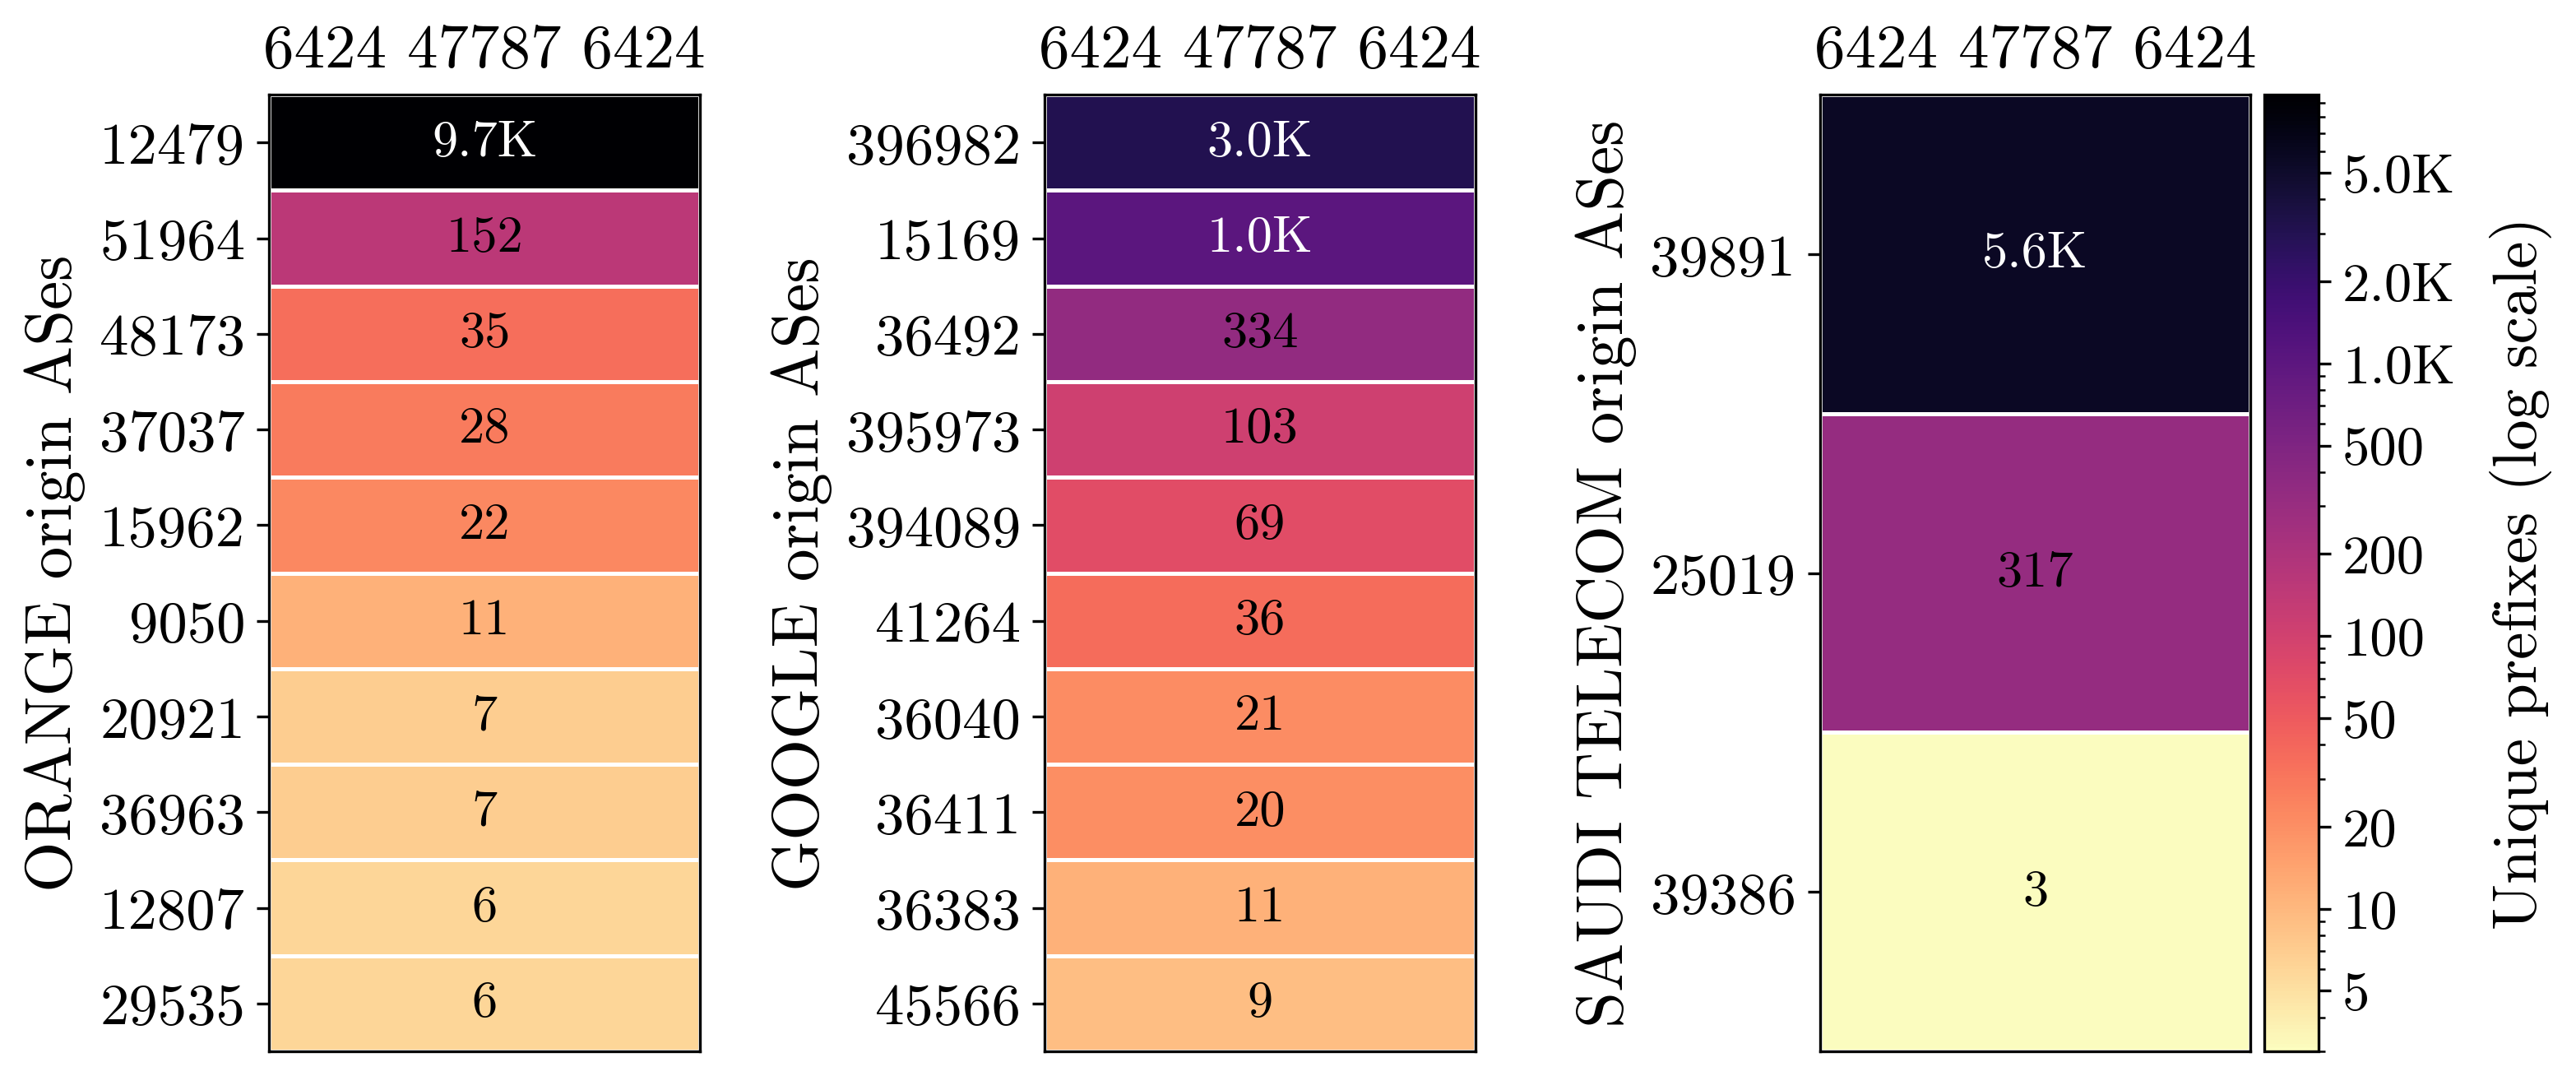


RS: 6424 47787 6424
Unique prefixes: 216,027
Organizations: 21,733
Origin ASes: 23,669
Top organizations: ['ORANGE', 'GOOGLE', 'SAUDI TELECOM COMPANY JSC']
----------------------------------------------------------------------


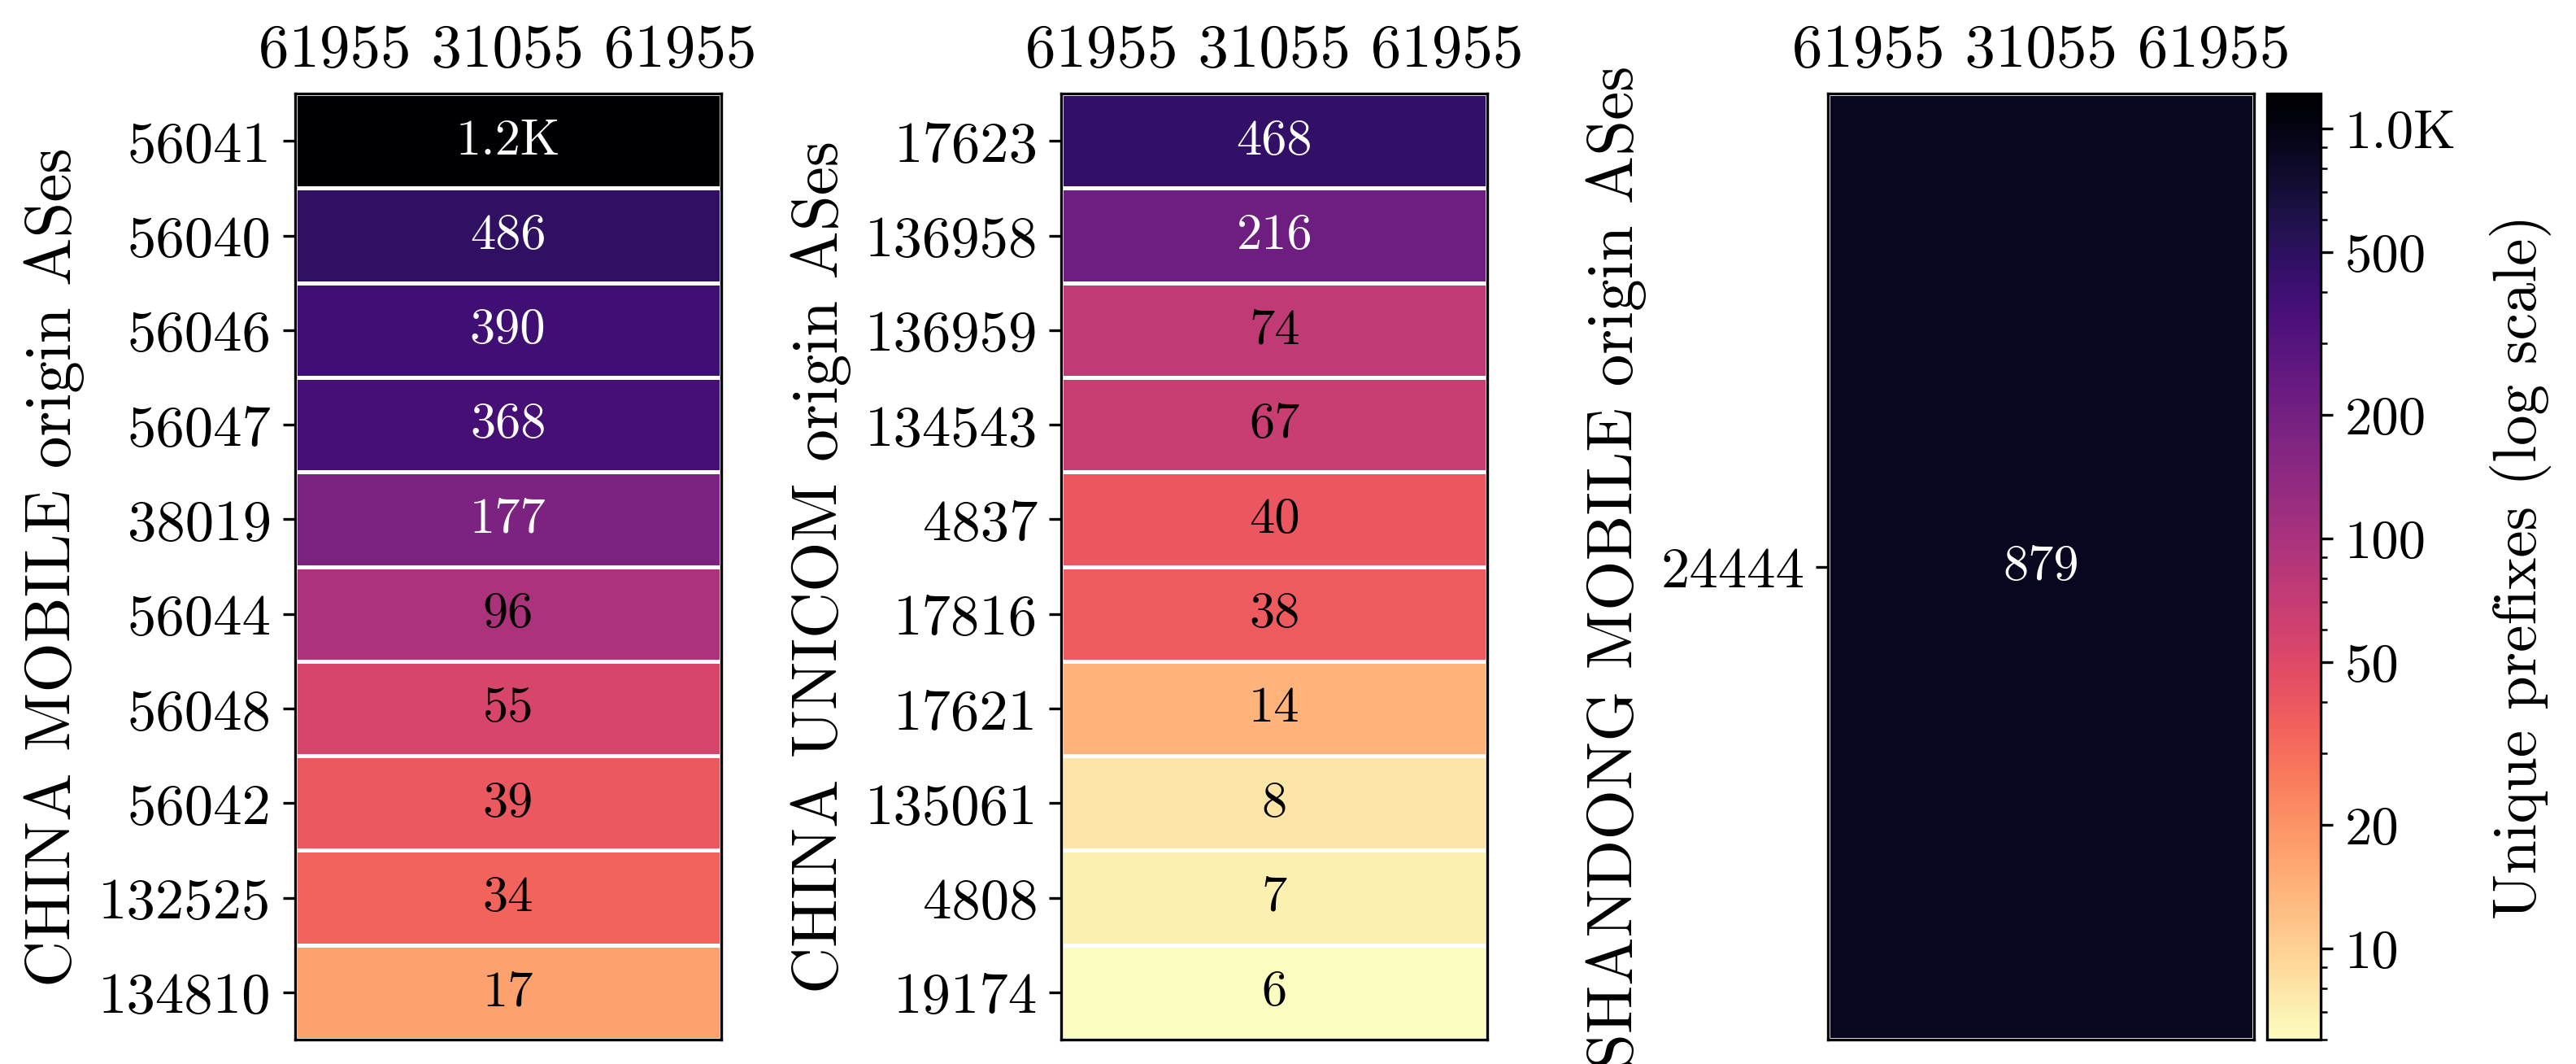


RS: 61955 31055 61955
Unique prefixes: 17,442
Organizations: 1,834
Origin ASes: 1,957
Top organizations: ['CHINA MOBILE', 'CHINA UNICOM', 'SHANDONG MOBILE COMMUNICATION']
----------------------------------------------------------------------


In [71]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

INPUT = ROOT / "data/sibling_ases/organization_sibling_rs.rows.refined.parquet"

TARGET_RSS = [
    "131477 65511 140096 131477",
    "6424 47787 6424",
    "61955 31055 61955",
]

ORG_LABELS = {
    "SAUDI TELECOM COMPANY JSC": "SAUDI TELECOM",
    "SHANDONG MOBILE COMMUNICATION": "SHANDONG MOBILE",
}

TOP_N_ORGS = 3
TOP_N_ORIGINS = 10
FONT_SIZE = 18

df = pd.read_parquet(
    INPUT,
    columns=["organization", "origin_as", "prefix", "poisoned_segment"],
)

df["organization"] = df["organization"].astype(str).str.strip()
df["poisoned_segment"] = df["poisoned_segment"].astype(str).str.strip()
df["origin_as"] = pd.to_numeric(df["origin_as"]).astype("int64")


def human(x):
    if x >= 1_000_000:
        return f"{x / 1_000_000:.1f}M"
    if x >= 1_000:
        return f"{x / 1_000:.1f}K"
    return f"{int(x)}"


def log_ticks(vmin, vmax):
    return [
        base * 10**exp
        for exp in range(
            int(np.floor(np.log10(vmin))),
            int(np.ceil(np.log10(vmax))) + 1,
        )
        for base in (1, 2, 5)
        if vmin <= base * 10**exp <= vmax
    ]


for target_rs in TARGET_RSS:
    target = df.loc[df["poisoned_segment"] == target_rs].copy()

    if target.empty:
        raise ValueError(f"No observations for RS: {target_rs}")

    org_ranking = (
        target.groupby("organization")["prefix"]
        .nunique()
        .sort_values(ascending=False)
    )

    top_orgs = org_ranking.head(TOP_N_ORGS).index.tolist()

    if len(top_orgs) != TOP_N_ORGS:
        raise ValueError(f"Expected three organizations for {target_rs}")

    if target_rs == "6424 47787 6424":
        google = [org for org in top_orgs if "GOOGLE" in org.upper()]
        telecom = [
            org for org in top_orgs
            if "TELECOM COMPANY JSC" in org.upper()
        ]
        others = [
            org for org in top_orgs
            if org not in google and org not in telecom
        ]
        top_orgs = others + google + telecom

    heat = (
        target.loc[target["organization"].isin(top_orgs)]
        .groupby(["organization", "origin_as"], as_index=False)
        .agg(value=("prefix", "nunique"))
    )

    heat = (
        heat.sort_values(
            ["organization", "value", "origin_as"],
            ascending=[True, False, True],
        )
        .groupby("organization", group_keys=False)
        .head(TOP_N_ORIGINS)
    )

    positive = heat.loc[heat["value"] > 0, "value"]

    if positive.empty:
        raise ValueError(f"No positive heatmap values for {target_rs}")

    vmin = max(1, float(positive.min()))
    vmax = float(positive.max())

    if vmax <= vmin:
        vmax = vmin * 10

    norm = LogNorm(vmin=vmin, vmax=vmax)

    fig, axes = plt.subplots(
        1, TOP_N_ORGS, figsize=(11, 5.1), dpi=300
    )

    for ax, org in zip(axes, top_orgs):
        sub = (
            heat.loc[heat["organization"] == org]
            .sort_values(
                ["value", "origin_as"],
                ascending=[False, True],
            )
            .head(TOP_N_ORIGINS)
        )

        values = sub[["value"]].to_numpy()
        asns = sub["origin_as"].tolist()

        im = ax.imshow(
            values,
            aspect="auto",
            interpolation="nearest",
            norm=norm,
            cmap="magma_r",
        )

        for y in np.arange(-0.5, len(asns), 1):
            ax.axhline(y, color="white", linewidth=1.2)

        ax.axvline(-0.5, color="white", linewidth=1.2)
        ax.axvline(0.5, color="white", linewidth=1.2)

        for i, value in enumerate(values.flatten()):
            ax.text(
                0, i, human(value),
                ha="center",
                va="center",
                fontsize=FONT_SIZE - 3,
                fontweight="bold",
                color="white" if value >= vmax * 0.08 else "black",
            )

        title = (
            "131477 * 131477"
            if target_rs == "131477 65511 140096 131477"
            else target_rs
        )

        ax.set_title(title, fontsize=FONT_SIZE, pad=8)
        ax.set_xticks([])
        ax.set_yticks(range(len(asns)), [str(asn) for asn in asns])

        org_name = ORG_LABELS.get(org, re.sub(r"\s+", " ", org))

        ax.set_ylabel(
            f"{org_name} origin ASes",
            fontsize=FONT_SIZE + 1,
        )
        ax.tick_params(axis="y", labelsize=FONT_SIZE - 1)

    fig.subplots_adjust(
        left=0.11,
        right=0.84,
        bottom=0.12,
        top=0.88,
        wspace=0.80,
    )

    pos = axes[-1].get_position()
    cax = fig.add_axes([0.845, pos.y0, 0.020, pos.height])
    cbar = fig.colorbar(im, cax=cax)

    ticks = log_ticks(vmin, vmax)
    cbar.set_ticks(ticks)
    cbar.ax.set_yticklabels(
        [human(tick) for tick in ticks],
        fontsize=FONT_SIZE - 2,
    )
    cbar.set_label(
        "Unique prefixes (log scale)",
        fontsize=FONT_SIZE,
        labelpad=10,
    )

    plt.show()
    plt.close(fig)

    print(f"\nRS: {target_rs}")
    print(f"Unique prefixes: {target['prefix'].nunique():,}")
    print(f"Organizations: {target['organization'].nunique():,}")
    print(f"Origin ASes: {target['origin_as'].nunique():,}")
    print(f"Top organizations: {top_orgs}")
    print("-" * 70)

In [72]:
import pyarrow.parquet as pq

for month in ["2024.02", "2024.10"]:
    base = ROOT / "data/visibility" / month

    checkpoint = base / "all_collectors.prefix_visibility.parquet"
    poisoning = sorted((base / "poisoning").glob("*.poisoning.parquet"))

    print(f"\n{'=' * 60}")
    print(f"MONTH: {month}")
    print(f"{'=' * 60}")

    print(f"\nCheckpoint rows: {pq.ParquetFile(checkpoint).metadata.num_rows:,}")
    print("Checkpoint schema:")
    print(pq.read_schema(checkpoint))

    print(f"\nPoisoning files: {len(poisoning)}")

    if poisoning:
        print("Poisoning schema:")
        print(pq.read_schema(poisoning[0]))


MONTH: 2024.02

Checkpoint rows: 2,186,902
Checkpoint schema:
prefix: large_string
collector: large_string
collector_peer_ases: large_list<item: int64>
  child 0, item: int64
collector_peer_ips: large_list<item: large_string>
  child 0, item: large_string
num_collector_sessions: int64

Poisoning files: 667
Poisoning schema:
date: string
rib_timestamp: int64
collector: string
peer_asn: int64
peer_ip: string
prefix: string
next_hop: string
as_path: string
origin: string
communities: string
cleaned_aspath: string
introducing_as: int64
appearing_ases: list<element: int64>
  child 0, element: int64
rs_path: string
num_repeated_asns: int64
had_as_set: bool
as_set_tokens_removed: int64
origin_from_single_as_set: bool
ambiguous_origin_as_set: bool
origin_as_set_raw: string

MONTH: 2024.10

Checkpoint rows: 5,236,794
Checkpoint schema:
prefix: large_string
collector: large_string
collector_peer_ases: large_list<item: int64>
  child 0, item: int64
collector_peer_ips: large_list<item: large_stri

In [73]:

from pathlib import Path

import numpy as np
import polars as pl
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter


ROOT = Path.cwd().resolve()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent

DATA = ROOT / "data/visibility"
FIGURES = ROOT / "figures/visibility"
FIGURES.mkdir(parents=True, exist_ok=True)

MONTHS = [
    ("2024.02", "february_2024"),
    ("2024.10", "october_2024"),
]

VISIBILITY = {}


def compute_visibility(month):
    base = DATA / month
    files = sorted((base / "poisoning").glob("*.poisoning.parquet"))
    checkpoint = base / "all_collectors.prefix_visibility.parquet"

    if not files:
        raise FileNotFoundError(f"No poisoning files found: {base}")
    if not checkpoint.exists():
        raise FileNotFoundError(checkpoint)

    print(f"\n{'=' * 65}")
    print(f"MONTH: {month}")
    print(f"Poisoning files: {len(files):,}")

    observations = (
        pl.scan_parquet(files)
        .select([
            "prefix", "rs_path", "collector",
            "peer_asn", "peer_ip",
        ])
        .with_columns(
            pl.concat_str(
                ["collector", "peer_ip"],
                separator="|",
                ignore_nulls=False,
            ).alias("_session")
        )
    )

    patterns = (
        observations
        .group_by(["prefix", "rs_path"])
        .agg([
            pl.col("collector").n_unique().alias("num_pattern_collectors"),
            pl.col("peer_asn").n_unique().alias("num_pattern_peer_ases"),
            pl.col("_session").n_unique().alias("num_pattern_sessions"),
        ])
        .collect()
    )

    print(f"Prefix-RS patterns: {patterns.height:,}")
    print(f"Distinct RSs: {patterns['rs_path'].n_unique():,}")

    compact = pl.scan_parquet(checkpoint)

    collectors = (
        compact
        .select(["prefix", "collector"])
        .unique()
        .group_by("prefix")
        .agg(
            pl.col("collector")
            .n_unique()
            .alias("num_prefix_collectors")
        )
        .collect()
    )

    peer_ases = (
        compact
        .select(["prefix", "collector_peer_ases"])
        .explode("collector_peer_ases")
        .drop_nulls()
        .unique()
        .group_by("prefix")
        .agg(
            pl.col("collector_peer_ases")
            .n_unique()
            .alias("num_prefix_peer_ases")
        )
        .collect()
    )

    sessions = (
        compact
        .select(["prefix", "collector", "collector_peer_ips"])
        .explode("collector_peer_ips")
        .drop_nulls()
        .with_columns(
            pl.concat_str(
                ["collector", "collector_peer_ips"],
                separator="|",
            ).alias("_session")
        )
        .select(["prefix", "_session"])
        .unique()
        .group_by("prefix")
        .agg(
            pl.col("_session")
            .n_unique()
            .alias("num_prefix_sessions")
        )
        .collect()
    )

    denominators = (
        collectors
        .join(peer_ases, on="prefix", how="inner")
        .join(sessions, on="prefix", how="inner")
    )

    print(f"Denominator prefixes: {denominators.height:,}")

    visibility = patterns.join(
        denominators,
        on="prefix",
        how="left",
        validate="m:1",
    )

    if visibility.select(
        pl.any_horizontal(
            pl.col("num_prefix_collectors").is_null(),
            pl.col("num_prefix_peer_ases").is_null(),
            pl.col("num_prefix_sessions").is_null(),
        ).sum()
    ).item():
        raise ValueError("Missing prefix denominators")

    visibility = visibility.with_columns([
        (
            pl.col("num_pattern_collectors")
            / pl.col("num_prefix_collectors") * 100
        ).alias("collector_visibility_pct"),
        (
            pl.col("num_pattern_peer_ases")
            / pl.col("num_prefix_peer_ases") * 100
        ).alias("peer_visibility_pct"),
        (
            pl.col("num_pattern_sessions")
            / pl.col("num_prefix_sessions") * 100
        ).alias("session_visibility_pct"),
    ])

    for col in [
        "collector_visibility_pct",
        "peer_visibility_pct",
        "session_visibility_pct",
    ]:
        invalid = visibility.filter(
            pl.col(col).is_null()
            | ~pl.col(col).is_finite()
            | (pl.col(col) < 0)
            | (pl.col(col) > 100.000001)
        )
        if invalid.height:
            raise ValueError(
                f"{month}: {invalid.height:,} invalid values in {col}"
            )

    print(f"Visibility records: {visibility.height:,}")
    return visibility


for month, label in MONTHS:
    VISIBILITY[month] = compute_visibility(month)



MONTH: 2024.02
Poisoning files: 667
Prefix-RS patterns: 106,168
Distinct RSs: 1,215
Denominator prefixes: 98,151
Visibility records: 106,168

MONTH: 2024.10
Poisoning files: 713
Prefix-RS patterns: 261,470
Distinct RSs: 1,317


: 

In [ ]:

from pathlib import Path

import numpy as np
import polars as pl
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter


ROOT = Path.cwd().resolve()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent

DATA = ROOT / "data/visibility"
FIGURES = ROOT / "figures/visibility"
FIGURES.mkdir(parents=True, exist_ok=True)

MONTHS = [
    ("2024.02", "february_2024"),
    ("2024.10", "october_2024"),
]

VISIBILITY = {}


def compute_visibility(month):
    base = DATA / month
    files = sorted((base / "poisoning").glob("*.poisoning.parquet"))
    checkpoint = base / "all_collectors.prefix_visibility.parquet"

    if not files:
        raise FileNotFoundError(f"No poisoning files found: {base}")
    if not checkpoint.exists():
        raise FileNotFoundError(checkpoint)

    print(f"\n{'=' * 65}")
    print(f"MONTH: {month}")
    print(f"Poisoning files: {len(files):,}")

    observations = (
        pl.scan_parquet(files)
        .select([
            "prefix", "rs_path", "collector",
            "peer_asn", "peer_ip",
        ])
        .with_columns(
            pl.concat_str(
                ["collector", "peer_ip"],
                separator="|",
                ignore_nulls=False,
            ).alias("_session")
        )
    )

    patterns = (
        observations
        .group_by(["prefix", "rs_path"])
        .agg([
            pl.col("collector").n_unique().alias("num_pattern_collectors"),
            pl.col("peer_asn").n_unique().alias("num_pattern_peer_ases"),
            pl.col("_session").n_unique().alias("num_pattern_sessions"),
        ])
        .collect()
    )

    print(f"Prefix-RS patterns: {patterns.height:,}")
    print(f"Distinct RSs: {patterns['rs_path'].n_unique():,}")

    compact = pl.scan_parquet(checkpoint)

    collectors = (
        compact
        .select(["prefix", "collector"])
        .unique()
        .group_by("prefix")
        .agg(
            pl.col("collector")
            .n_unique()
            .alias("num_prefix_collectors")
        )
        .collect()
    )

    peer_ases = (
        compact
        .select(["prefix", "collector_peer_ases"])
        .explode("collector_peer_ases")
        .drop_nulls()
        .unique()
        .group_by("prefix")
        .agg(
            pl.col("collector_peer_ases")
            .n_unique()
            .alias("num_prefix_peer_ases")
        )
        .collect()
    )

    sessions = (
        compact
        .select(["prefix", "collector", "collector_peer_ips"])
        .explode("collector_peer_ips")
        .drop_nulls()
        .with_columns(
            pl.concat_str(
                ["collector", "collector_peer_ips"],
                separator="|",
            ).alias("_session")
        )
        .select(["prefix", "_session"])
        .unique()
        .group_by("prefix")
        .agg(
            pl.col("_session")
            .n_unique()
            .alias("num_prefix_sessions")
        )
        .collect()
    )

    denominators = (
        collectors
        .join(peer_ases, on="prefix", how="inner")
        .join(sessions, on="prefix", how="inner")
    )

    print(f"Denominator prefixes: {denominators.height:,}")

    visibility = patterns.join(
        denominators,
        on="prefix",
        how="left",
        validate="m:1",
    )

    if visibility.select(
        pl.any_horizontal(
            pl.col("num_prefix_collectors").is_null(),
            pl.col("num_prefix_peer_ases").is_null(),
            pl.col("num_prefix_sessions").is_null(),
        ).sum()
    ).item():
        raise ValueError("Missing prefix denominators")

    visibility = visibility.with_columns([
        (
            pl.col("num_pattern_collectors")
            / pl.col("num_prefix_collectors") * 100
        ).alias("collector_visibility_pct"),
        (
            pl.col("num_pattern_peer_ases")
            / pl.col("num_prefix_peer_ases") * 100
        ).alias("peer_visibility_pct"),
        (
            pl.col("num_pattern_sessions")
            / pl.col("num_prefix_sessions") * 100
        ).alias("session_visibility_pct"),
    ])

    for col in [
        "collector_visibility_pct",
        "peer_visibility_pct",
        "session_visibility_pct",
    ]:
        invalid = visibility.filter(
            pl.col(col).is_null()
            | ~pl.col(col).is_finite()
            | (pl.col(col) < 0)
            | (pl.col(col) > 100.000001)
        )
        if invalid.height:
            raise ValueError(
                f"{month}: {invalid.height:,} invalid values in {col}"
            )

    print(f"Visibility records: {visibility.height:,}")
    return visibility


for month, label in MONTHS:
    VISIBILITY[month] = compute_visibility(month)
